# From Look-Alikes to Action: The Story of Maria
**INFO 5810 – Data Analysis and Knowledge Discovery**

*An imagined case, built on simulated data.*

---

**Maria has been a customer for six years.** Last month her car was damaged in a collision and she filed a claim. A few days later a letter arrived: *"Your claim has been selected for additional review."* She had done nothing wrong. The review took three weeks. When her policy came up for renewal, she did not renew.

This notebook is the story of what the insurer should have asked, and of everything it can learn from one false alarm. Along the way it uses nearly everything from the semester: a model, similarity, clusters, graphs, three kinds of database, Cypher, causal reasoning, and customer relationship management (CRM).

> **Narrate:** I want to tell you a story about Maria that summarizes our semester. Everything I say is also in this notebook, so dig deep. The story is in the indented boxes marked Narrate, the ideas are in the Concept boxes, and the details are in the Dig deeper sections underneath.

### How to read this notebook
| Layer | What it is |
|---|---|
| **Narrate** | The story in a few sentences. Read only these and you have the whole plot. |
| **Concept** | The idea behind the step, in plain language. |
| **Dig deeper** | The mechanics, for anyone who wants to see how it works. |
| **Code and output** | Every number in the story, produced live. |

### Maria's questions, and what answers each
| Part | Maria's question | What we use to answer it |
|---|---|---|
| 1 | Why was I flagged? | A model, false positives |
| 2 | What is in the insurer's files about me? | Closed claims, customer records, an interaction log |
| 3 | Who else looks like me? | TF-IDF similarity, retrieval, a vector database (ChromaDB) |
| 4 | Which group am I in? | Clustering, customer segments |
| 5 | How am I connected to everything else? | A knowledge graph, Neo4j, Cypher, customer 360 |
| 6 | Which kind of database answers which kind of question? | SQL, Cypher and vector search side by side |
| 7 | Is my repair shop to blame? | A causal graph, adjustment, do() (rung 2) |
| 8 | Did the false alarm cost the insurer my business? | Retention and adjustment (rung 2) |
| 9 | What would reviewing more claims be worth? | A business case |
| 10 | What would have happened to me, and what do I need now? | Counterfactuals and recourse (rung 3) |
| 11 | Does the fix work? | A randomized pilot (rung 2) |
| 12 | What should the insurer do? | A grounded case file |
| 13 | What should worry us? | Limits, privacy, fairness |

**The thread through the whole notebook.** Everything we build sits on the ladder. Similarity, clusters and graph structure are **rung 1**: they find what goes with what. Testing a hypothesis about an action is **rung 2**. Maria's own plan is **rung 3**. The skill is knowing which rung each finding lives on, and not writing a rung 1 finding up as a cause.

**A second thread: Maria is a customer.** Every claim belongs to a person who may or may not renew next year. CRM keeps one record of each customer and every contact with them, and uses it to decide what to do next. We add that layer to the same case, so the analysis ends in something an insurer can act on and measure.

## The toolbox: what we use, and why

> **Narrate:** Every story needs a cast. Ours has a person, Maria, and a set of tools. Some tools are databases, because Maria's information lives in three different kinds of storage. Some are Python libraries, because we need to calculate, draw and test. I will introduce each one the first time we need it, and say why we chose it. This table is the cast list, so you can see the whole company before the story starts.

| Tool | What kind of thing it is | What it does for Maria's story | Why this one, and what else we could have used |
|---|---|---|---|
| **Python 3.11+ in a Jupyter notebook** | Language and working surface | Holds the story, the code and the results on one page | A notebook lets reading, running and checking happen together. A script would hide the story. |
| **uv** | Package and environment manager | Installs every library at the versions we tested, with `uv sync` | One command, same versions for everyone. `pip` with a `requirements.txt` also works, but is slower and less strict. |
| **NumPy** | Library: fast arrays | Does the arithmetic behind similarity, clustering and the simulated worlds | Everything numeric in Python sits on it. We use it to build the algorithms by hand. |
| **pandas** | Library: tables in memory | Holds claims, customers and interactions as tables; groups and totals | The standard tool for tables. Its `groupby` is the same idea as SQL's `GROUP BY`. |
| **scikit-learn** | Library: machine learning | Trains the logistic regression that flags claims, and **checks** our hand-built TF-IDF | We build TF-IDF and k-means ourselves so nothing is a black box, and use the library as a referee. |
| **matplotlib** | Library: charts | Draws the cluster picture, the graph picture and the bar charts | The base plotting library in Python. Others (Plotly, Altair) add interactivity we do not need on a recording. |
| **NetworkX** | Library: graphs in memory | Holds the claim network and the causal diagram; answers graph questions in Python | Small, free and needs no server. It is how we first see a graph before putting one in a database. |
| **Neo4j + Cypher** | **Graph database** and its query language | Stores the same network on disk and answers "who is connected to whom" by drawing a pattern | Built to follow connections several hops out. The same question in SQL needs a join for every hop. |
| **ChromaDB** | **Vector database** | Stores each note as a list of numbers and finds the closest notes to Maria's | Built to rank by similarity, with filters. A table or a graph is not built for "reads like". |
| **SQLite** (`sqlite3`) | **Relational database** | Stores the claims, customers and interactions as tables; answers totals and joins in SQL | Ships with Python, one file, nothing to install. A server database (PostgreSQL) would do the same job at larger scale. |
| **python-dotenv** | Library: reads a `.env` file | Keeps the Neo4j password and the Groq key out of the notebook | Passwords in code get committed to GitHub by accident. A `.env` file that Git ignores does not. |
| **Groq API** | Hosted language model | Optionally writes the final summary, only from the facts we retrieved | Fast and has a free tier. Any model could do it. The point is the grounding, not the vendor. |

<details open>
<summary><b>Dig deeper: documentation for each tool</b></summary>

| Tool | Where to read more |
|---|---|
| Jupyter and VS Code notebooks | https://jupyter.org/documentation and https://code.visualstudio.com/docs/datascience/jupyter-notebooks |
| uv | https://docs.astral.sh/uv/ |
| NumPy | https://numpy.org/doc/ |
| pandas | https://pandas.pydata.org/docs/ (start with "10 minutes to pandas") |
| scikit-learn | https://scikit-learn.org/stable/user_guide.html |
| matplotlib | https://matplotlib.org/stable/ |
| NetworkX | https://networkx.org/documentation/stable/ |
| Neo4j Cypher manual | https://neo4j.com/docs/cypher-manual/current/ |
| Neo4j Python driver | https://neo4j.com/docs/python-manual/current/ |
| ChromaDB | https://docs.trychroma.com/ |
| SQLite and Python's `sqlite3` | https://www.sqlite.org/docs.html and https://docs.python.org/3/library/sqlite3.html |
| python-dotenv | https://pypi.org/project/python-dotenv/ |
| Groq | https://console.groq.com/docs |
| Causal ideas (the three rungs) | Judea Pearl and Dana Mackenzie, *The Book of Why*; Pearl, Glymour and Jewell, *Causal Inference in Statistics: A Primer* |

The project's `README.md` and the `docs/` folder cover installing and starting everything.
</details>

<details open>
<summary><b>Dig deeper: three kinds of database in one picture</b></summary>

| | Relational | Graph | Vector |
|---|---|---|---|
| **Stores** | Rows in tables | Nodes and relationships | A list of numbers per item |
| **Finds things by** | Matching column values and joining tables on shared keys | Following relationships | Distance between lists of numbers |
| **Strong at** | Totals, filters, reports, anything with a fixed shape | Networks, paths, "friends of friends" | "More like this", meaning-based search |
| **Weak at** | Many-hop connection questions | Plain totals over huge tables | Exact answers: it ranks, it does not prove |
| **In this notebook** | SQLite | Neo4j (and NetworkX in memory) | ChromaDB |
| **Language** | SQL | Cypher | A query vector plus optional filters |

Real systems often use all three, the way this story does.
</details>

## Part 0: Where we have been (quick recap)

> **Narrate:** Before Maria's story, a minute on what we are carrying with us. Nothing in this story is new. Every tool is one we have already used this semester. What is new is using all of them on one person, to see how they fit together.

> **Concept:** A semester is a toolbox. The skill is not any single tool but knowing which one answers which question, and how sure you may be of the answer.

Almost everything today reuses an earlier idea. Here is the short version.

| Idea we already know | One-line reminder | Where it comes back today |
|---|---|---|
| **The ladder** | Seeing needs data. Doing needs data plus a graph. Imagining one case needs data, a graph and equations. | Organizes the whole case file |
| **A model that flags claims** | A logistic regression turns four inputs into a fraud score, and flags at 0.5 | Maria is flagged again, and we ask what to do about it |
| **False positive** | A legitimate claim the model flags | Maria is one |
| **TF-IDF and cosine similarity** | Count words, give rare words more weight, compare notes by angle | Retrieving claims that read like Maria's |
| **Graph databases** | Nodes, edges, and queries that follow them (Cypher) | The knowledge graph of claims, shops and areas |
| **Relational database (SQL)** | Tables of rows and columns, joined by shared keys | Customer and claim records, and totals by group |
| **Vector database** | Stores numbers that describe each item and returns the closest ones | Finding notes that read like Maria's |
| **Graph RAG** | Retrieve facts first, then ground the answer in exactly those facts | The case file is built from retrieved facts |
| **Fork, confounder, backdoor path** | A common cause makes two things move together; adjust for it | Why a shop can look guilty without being guilty |
| **do() and adjustment** | Force a variable, or hold the confounder fixed | Testing whether a shop really raises fraud |
| **Structural causal model** | Equations plus each case's own noise | Maria's replay |
| **Counterfactual and recourse** | What would it take for *this* person, using only actions she can take | Maria's plan |

**What CRM means here.** *Customer relationship management* is the practice of keeping one joined-up record of each customer and every contact with them, then using it to decide what to do next. Each piece of CRM has a counterpart in this notebook:

| CRM idea | What it is in this notebook |
|---|---|
| **Customer record** | Tenure, annual premium and renewal outcome for each claimant |
| **Interaction log** | Every call, document request, review and settlement, stored as a time-stamped record on the claim |
| **Segments** | The claim groups from clustering, read as groups of customers |
| **Customers like this one** | Retrieval over the adjuster notes |
| **Relationship map** | The knowledge graph that links customers, claims, shops and adjusters |
| **Customer 360** | One query that returns everything we know about one customer |
| **Next best action** | The recommended step for Maria (the case file) |
| **Closed loop** | Log the action, test it with a pilot, learn from the result |

**The ladder, one more time**

| Rung | Kind of question | What you need |
|---|---|---|
| 1. **Seeing** | What goes with what? | Data |
| 2. **Doing** | What happens to a group if we *make* something happen? | Data and a graph |
| 3. **Imagining** | What would have happened to *this* case if something had been different? | Data, a graph and equations |

### Setup
The first cell checks that the Neo4j driver is installed (run `uv sync` once in the project folder if it is not). The next one reads your connection settings from a `.env` file (the same three names as the earlier graph demo: `NEO4J_URI`, `NEO4J_USER`, `NEO4J_PASSWORD`) or from your environment. **If no Neo4j password is found, every Neo4j cell is skipped and the notebook still runs end to end with NetworkX.**

> **Concept: the ledger.** As the story moves along, we keep a **ledger**: one row for each question Maria asks, with the tool that answered it, the rung of evidence, and the number we found. The rows are filled in by the code in each part, so every figure in the ledger is computed, not typed. We show it in full at two checkpoints and at the end.

> **Narrate:** Before the story starts we check that the tools are in the room. The first cell makes sure the Neo4j driver is installed. The second loads the libraries and reads the passwords from a `.env` file. If the file has no Neo4j password, the graph database simply sits out, and everything else still runs.
>
> **Tool:** `python-dotenv` reads the `.env` file. The `neo4j` package is the Python driver that talks to the database. `uv sync` installed both, along with everything else, in one step.

In [1]:
try:
    from neo4j import GraphDatabase
except ImportError as e:
    raise ImportError("The neo4j driver is missing. Run `uv sync` in the project folder, then select the .venv kernel.") from e

In [2]:
import os, re, json, warnings, logging
from pathlib import Path
warnings.filterwarnings("ignore")
logging.disable(logging.CRITICAL)

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass                      # no python-dotenv: set NEO4J_PASSWORD in your environment instead

NEO4J_URI      = os.environ.get("NEO4J_URI", "bolt://localhost:7687")
NEO4J_USER     = os.environ.get("NEO4J_USER", "neo4j")
NEO4J_PASSWORD = os.environ.get("NEO4J_PASSWORD")
GROQ_API_KEY   = os.environ.get("GROQ_API_KEY")          # optional, used only in the last part

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_colwidth", 120)

NEO4J_OK, driver = False, None
if NEO4J_PASSWORD:
    try:
        driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))
        driver.verify_connectivity()
        NEO4J_OK = True
        print(f"Connected to Neo4j at {NEO4J_URI}")
    except Exception as e:
        print("Could not connect to Neo4j:", type(e).__name__, "-", str(e)[:140])
else:
    print("No NEO4J_PASSWORD found in .env or the environment.")
if not NEO4J_OK:
    print("Neo4j cells will be skipped. Everything else runs with NetworkX.")

def run_cypher(query, **params):
    with driver.session() as session:
        return [record.data() for record in session.run(query, **params)]

def show_cypher(query, **params):
    print(query.strip())
    if not NEO4J_OK:
        print("\n(Neo4j not connected: skipped. The NetworkX answer above asks the same question.)")
        return None
    return pd.DataFrame(run_cypher(query, **params))

# ----- The ledger: what we know about Maria so far. Each part adds one row, using numbers computed in that part. -----
from IPython.display import display
ledger = []
def note(part, question, tool, rung, found):
    ledger.append({"Part": part, "Maria asks": question, "Tool": tool, "Rung": rung, "What we found": found})

def show_ledger(title):
    print(title)
    display(pd.DataFrame(ledger).style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))

Connected to Neo4j at bolt://localhost:7687


## Part 1: Maria's false alarm, and what the insurer does next

> **Narrate:** A model flagged Maria's claim. Three weeks later a person proved the model wrong. The insurer could shrug and move on. Instead it asks five questions about her, and each one is answered by a different tool from this semester. Those five questions are the rest of the story.

> **Concept:** A **false positive** is a legitimate case the model flags by mistake. A flag is not just a prediction. It is an **action** the insurer takes, and actions have consequences for the person on the receiving end.

### The story so far
The insurer's model flagged **Maria's** claim for an extra fraud review. A full review later confirmed that her claim was **legitimate**. The flag was a false alarm, a **false positive**.

Maria was told two things: *why* she was flagged, and *what would have helped her*. Now the insurer's analysts ask bigger questions about the same case:

1. **Who else looks like Maria?** Did claims that read like hers turn out to be fraud?
2. **What network is her claim part of?** Which shop, which area, which adjuster?
3. **Is any of that a cause?** If the network looks risky, should the insurer act on the network?
4. **What does Maria herself need?**
5. **What did the flag cost the insurer as a business?** Maria had been a customer for six years. Did she stay?

We will build a **case file** that answers all five, one rung at a time.

| Part of the case file | Tool | Rung | Question |
|---|---|---|---|
| Similar past claims | Similarity over adjuster notes (retrieval) | 1 | What did claims like hers turn out to be? |
| Groups of claims | Clustering | 1 | Which group does she fall into? |
| Her network | Knowledge graph (NetworkX and Neo4j) | 1 | Who and what is she connected to? |
| A hypothesis check | Graph, adjustment, do() | 2 | Is a pattern in the network a cause? |
| Her own plan | Counterfactual and recourse | 3 | What would it take for *her*? |
| Customers and retention | Customer record, interaction log, adjustment | 1 and 2 | Does a false alarm cost us customers? |
| Her renewal | Counterfactual | 3 | Would she have stayed if she had not been flagged? |
| Closing the loop | Randomized pilot | 2 | Does the next best action work? |

### The model, rebuilt
This is the same model as before: a logistic regression trained on 40,000 past claims, with Maria's file unchanged. The next two cells rebuild it. You have seen this machine, so we do not open it again.

<details open>
<summary><b>Dig deeper: what the model is</b></summary>

A logistic regression adds up weighted clues (prior claims, suspicious timing, receipts mismatch, witness conflict) and squeezes the total into a number between 0 and 1, the **score**. The insurer flags any claim scoring **0.5 or more**. The weights are learned from the 40,000 past claims, where the true outcome is known. The "history" below is simulated by equations we wrote ourselves, which is what lets us check every answer later.
</details>

> **Narrate:** Where does Maria's world come from? We built it. A short set of equations writes the claims, the receipts and the witness reports. That sounds like cheating, and in a way it is, on purpose: in real life no one hands you the answer key. Here we hold it back until the end, so that when we claim to have found a cause, we can check whether we were right.
>
> **Tool:** `numpy` draws the random numbers and `pandas` holds the table. `scikit-learn` then trains the flagging model, a logistic regression, on 40,000 past claims.

In [3]:
FRAUD_P = {(1, 1): 0.90, (1, 0): 0.55, (0, 1): 0.50, (0, 0): 0.03}   # P(FraudRisk = High | prior, timing)

def eq_receipts(fraud, docs, u):  return 4.0 + 3.0 * fraud - 0.5 * docs + u
def eq_witness(fraud, follow, u): return 1.0 + 3.0 * fraud - 1.5 * follow + u

def draw_noise(n, rng):
    return dict(prior=rng.uniform(size=n), timing=rng.uniform(size=n), fraud=rng.uniform(size=n),
                docs=rng.normal(0, 1.5, n), follow=rng.uniform(size=n),
                receipts=rng.normal(0, 1.2, n), witness=rng.normal(0, 1.5, n))

def world(U, do=None, docs_effect=-0.5):
    do = do or {}
    d = {}
    d["PriorClaims"]      = do.get("PriorClaims", (U["prior"] < 0.15).astype(int))
    d["SuspiciousTiming"] = do.get("SuspiciousTiming", (U["timing"] < 0.10).astype(int))
    p = np.vectorize(lambda a, b: FRAUD_P[(int(a), int(b))])(d["PriorClaims"], d["SuspiciousTiming"])
    d["FraudRisk"]        = do.get("FraudRisk", (U["fraud"] < p).astype(int))
    d["Docs"]             = do.get("Docs", 4 + 3.0 * d["PriorClaims"] + U["docs"])
    d["FollowUp"]         = do.get("FollowUp", (U["follow"] < 0.10).astype(int))
    d["Receipts"]         = do.get("Receipts", 4.0 + 3.0 * d["FraudRisk"] + docs_effect * d["Docs"] + U["receipts"])
    d["Witness"]          = do.get("Witness", eq_witness(d["FraudRisk"], d["FollowUp"], U["witness"]))
    return pd.DataFrame(d)

history = world(draw_noise(40000, np.random.default_rng(13)))
features = ["PriorClaims", "SuspiciousTiming", "Receipts", "Witness"]
model = LogisticRegression(max_iter=2000).fit(history[features], history["FraudRisk"])

In [4]:
maria = dict(PriorClaims=1, SuspiciousTiming=0, Docs=4.5, FollowUp=0, FraudRisk=0, Receipts=3.6, Witness=3.0)
p_maria = model.predict_proba(pd.DataFrame([maria])[features])[0, 1]

print(pd.DataFrame([maria], index=["Maria"]).to_string())
print(f"\nModel's probability that Maria's claim is high fraud risk: {p_maria:.3f}")
print("Decision:", "FLAGGED" if p_maria >= 0.5 else "fast track", "   |   Truth after full review: legitimate")
note("1", "Why was I flagged?", "Logistic regression", "1",
     f"Score {p_maria:.2f}, above the 0.5 cut-off. The review found her claim legitimate: a false positive.")

       PriorClaims  SuspiciousTiming  Docs  FollowUp  FraudRisk  Receipts  Witness
Maria            1                 0 4.500         0          0     3.600    3.000

Model's probability that Maria's claim is high fraud risk: 0.964
Decision: FLAGGED    |   Truth after full review: legitimate


> **Narrate:** There she is. Maria's clues, run through the model, give a score of 0.964. The cut-off is 0.5, so she is flagged. A review later finds her claim legitimate, so this is a false positive. Hold on to that number, 0.964. Everything that follows is the insurer asking what to do about it.

<details open>
<summary><b>Go further on your own: Part 1</b></summary>

- **Read:** the logistic regression section of the scikit-learn user guide (https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression).
- **Try:** change the 0.5 cut-off in the flagging rule to 0.3 and to 0.7. Count how many false alarms and how many missed frauds each gives. What does the insurer give up with each choice?
- **Think:** a false positive is not a free mistake. Name who pays for it in this story, and who pays for a missed fraud.
</details>

## Part 2: This quarter's closed claims

> **Narrate:** Before anyone can answer Maria's questions, we need the insurer's files. Six thousand claims from this quarter, a customer record for each claimant, and a log of every contact with them. This is the plain records layer, and it is where Maria's six years with the company live.

> **Concept:** Analysis starts with **records**. A table is rows and columns. Two tables can be **joined** when they share a key (here, the claim ID), so one customer's record can be matched to the claim she filed.

The analysts pull **6,000 claims from this quarter**, all of them fully reviewed, so each has a known outcome. Compared with the old history, each claim now has more recorded about it:

| Column | Meaning |
|---|---|
| ClaimID | An identifier |
| Area | The district where the loss occurred (Riverside or Northgate) |
| Shop | The repair shop that wrote the estimate |
| Adjuster | The adjuster who handled the claim |
| PriorClaims, SuspiciousTiming, Docs, FollowUp, Receipts, Witness | The same variables as before |
| FraudRisk | The outcome of the full review (1 = confirmed high fraud risk) |
| Note | The adjuster's free-text note |

The next cell produces the claims. **Do not worry about how yet.** We open the machine in Part 7. Treat the table as the insurer's records.

> **Narrate:** Now the insurer's files for this quarter. Six thousand closed claims, each with a shop, an area, an adjuster, some clues, and a short note the adjuster typed. The note matters, because in Part 3 it becomes the thing we compare.
>
> **Tool:** `pandas` DataFrames. A DataFrame is a table in memory, one row per claim. We will meet the same table again as a SQLite table in Part 6.

In [5]:
# ----- The machine that produced this quarter's claims. We open it up in Part 7. -----
SHOPS = ["Apex Auto Body", "Bayview Collision", "Crescent Repair", "Delta Motors", "Eastside Auto"]
AREAS = ["Riverside", "Northgate"]
P_SHOP  = {"Riverside": [.06, .60, .12, .11, .11], "Northgate": [.06, .05, .30, .30, .29]}
P_PRIOR = {"Riverside": 0.40, "Northgate": 0.08}
RING_P  = 0.85

def draw_noise2(n, rng):
    return dict(area=rng.uniform(size=n), prior=rng.uniform(size=n), timing=rng.uniform(size=n),
                shop=rng.uniform(size=n), adj=rng.uniform(size=n), fraud=rng.uniform(size=n),
                docs=rng.normal(0, 1.5, n), follow=rng.uniform(size=n),
                receipts=rng.normal(0, 1.2, n), witness=rng.normal(0, 1.5, n))

def pick_shop(area, u):
    return np.array([SHOPS[int(np.searchsorted(np.cumsum(P_SHOP[a]), x))] for a, x in zip(area, u)])

def world2(U, do=None):
    do = do or {}
    d = {}
    d["Area"]             = do.get("Area", np.where(U["area"] < 0.25, "Riverside", "Northgate"))
    pp                    = np.where(d["Area"] == "Riverside", P_PRIOR["Riverside"], P_PRIOR["Northgate"])
    d["PriorClaims"]      = do.get("PriorClaims", (U["prior"] < pp).astype(int))
    d["SuspiciousTiming"] = do.get("SuspiciousTiming", (U["timing"] < 0.10).astype(int))
    d["Shop"]             = do.get("Shop", pick_shop(d["Area"], U["shop"]))
    d["Adjuster"]         = do.get("Adjuster", np.array([f"Adjuster {int(k) + 1}" for k in np.minimum((U["adj"] * 6).astype(int), 5)]))
    p = np.vectorize(lambda a, b: FRAUD_P[(int(a), int(b))])(d["PriorClaims"], d["SuspiciousTiming"])
    p = np.where(d["Shop"] == "Apex Auto Body", RING_P, p)
    d["FraudRisk"]        = do.get("FraudRisk", (U["fraud"] < p).astype(int))
    d["Docs"]             = do.get("Docs", 4 + 3.0 * d["PriorClaims"] + U["docs"])
    d["FollowUp"]         = do.get("FollowUp", (U["follow"] < 0.10).astype(int))
    d["Receipts"]         = do.get("Receipts", eq_receipts(d["FraudRisk"], d["Docs"], U["receipts"]))
    d["Witness"]          = do.get("Witness", eq_witness(d["FraudRisk"], d["FollowUp"], U["witness"]))
    return pd.DataFrame(d)

PHRASES = {
    "prior1":  ["claimant has filed before", "an earlier claim is on file"],
    "prior0":  ["no earlier claims on file", "this is the first claim"],
    "timing":  ["loss reported shortly after coverage increased", "reported soon after the policy limit was raised"],
    "rec_hi":  ["several receipts do not match the estimate", "multiple receipts disagree with the estimate"],
    "rec_mid": ["a few receipts need follow-up", "some receipts require follow-up"],
    "rec_lo":  ["receipts match the estimate", "receipts agree with the estimate"],
    "wit_hi":  ["witness statements conflict", "witness accounts disagree with each other"],
    "wit_mid": ["witness gave minor differences", "witness account differs slightly"],
    "wit_lo":  ["witness statements are consistent", "witness accounts agree"],
    "doc_hi":  ["documentation is thorough", "paperwork is complete"],
    "doc_lo":  ["documentation is thin", "paperwork is sparse"],
    "doc_mid": ["documentation is adequate", "paperwork is acceptable"],
}
def write_note(r, rng=None):
    pick = (lambda k: PHRASES[k][int(rng.integers(2))]) if rng is not None else (lambda k: PHRASES[k][0])
    parts = [pick("prior1" if r.PriorClaims == 1 else "prior0")]
    if r.SuspiciousTiming == 1: parts.append(pick("timing"))
    parts.append(pick("rec_hi" if r.Receipts >= 3 else "rec_mid" if r.Receipts >= 1.5 else "rec_lo"))
    parts.append(pick("wit_hi" if r.Witness >= 3 else "wit_mid" if r.Witness >= 1.5 else "wit_lo"))
    parts.append(pick("doc_hi" if r.Docs >= 7 else "doc_lo" if r.Docs < 5 else "doc_mid"))
    parts.append(f"repair estimate from {r.Shop}")
    parts.append(f"loss occurred in the {r.Area} district")
    return "; ".join(parts) + "."

N = 6000
claims = world2(draw_noise2(N, np.random.default_rng(14)))
claims.insert(0, "ClaimID", [f"C{i:04d}" for i in range(N)])
note_rng = np.random.default_rng(99)
claims["Note"] = [write_note(r, note_rng) for r in claims.itertuples()]

maria_ctx = dict(ClaimID="Maria", Area="Riverside", Shop="Bayview Collision", Adjuster="Adjuster 3", **maria)
maria_note = write_note(pd.Series(maria_ctx))
claims[["ClaimID", "Area", "Shop", "Adjuster", "FraudRisk", "Receipts", "Witness", "Note"]].head(5)

,ClaimID,Area,Shop,Adjuster,FraudRisk,Receipts,Witness,Note
0,C0000,Northgate,Eastside Auto,Adjuster 4,0,4.630,-0.617,this is the first claim; multiple receipts disagree with the estimate; witness accounts agree; paperwork is sparse; ...
1,C0001,Northgate,Delta Motors,Adjuster 4,0,3.544,0.129,no earlier claims on file; reported soon after the policy limit was raised; multiple receipts disagree with the esti...
2,C0002,Northgate,Delta Motors,Adjuster 4,0,3.050,1.763,this is the first claim; several receipts do not match the estimate; witness account differs slightly; paperwork is ...
3,C0003,Northgate,Delta Motors,Adjuster 2,0,1.136,1.406,no earlier claims on file; receipts agree with the estimate; witness accounts agree; documentation is adequate; repa...
4,C0004,Northgate,Bayview Collision,Adjuster 1,1,6.775,4.472,no earlier claims on file; loss reported shortly after coverage increased; multiple receipts disagree with the estim...


Each row is one closed claim, and the last column is the adjuster's note, written in ordinary words. Maria's own note reads:

In [6]:
print(maria_note)

claimant has filed before; several receipts do not match the estimate; witness statements conflict; documentation is thin; repair estimate from Bayview Collision; loss occurred in the Riverside district.


### How well does the model do on this quarter?
Before we dig in, check the model on these new claims.

In [7]:
claims["Score"] = model.predict_proba(claims[features])[:, 1]
claims["Flagged"] = claims["Score"] >= 0.5
is_fraud = claims["FraudRisk"].values == 1
flag = claims["Flagged"].values

print(f"Share of this quarter's claims that are real fraud:  {is_fraud.mean():.1%}")
print(f"Share flagged by the model:                          {flag.mean():.1%}")
print(f"Share of real fraud the model catches (recall):      {flag[is_fraud].mean():.1%}")
print(f"Share of flags that are real fraud (precision):      {is_fraud[flag].mean():.1%}")
print(f"Share of legitimate claims flagged by error:         {flag[~is_fraud].mean():.1%}")

Share of this quarter's claims that are real fraud:  20.5%
Share flagged by the model:                          18.5%
Share of real fraud the model catches (recall):      84.0%
Share of flags that are real fraud (precision):      93.1%
Share of legitimate claims flagged by error:         1.6%


> **Narrate:** A quick check before we trust the model on new claims. It still works well on this quarter, though it misses more fraud than it did on the old history, and the next sections show where. That detail matters later, when the insurer asks where to look harder.

The model still works well. It misses a larger share of fraud than it did on the old history, though, and you will see why shortly.

### Each claim belongs to a customer (the CRM layer)
So far a claim is a row of clues. The insurer also knows the **customer** behind it, and keeps a **log of every contact** with that customer. These two records are the heart of CRM. We add two tables:

| Table | One row is | Columns |
|---|---|---|
| `customers` | One policyholder, linked to a claim | Tenure in years, annual premium, days to settle the claim, and whether the policy was renewed |
| `interactions` | One contact on a claim | The claim, what happened, and the day it happened (day 0 is the day the claim was filed) |

Maria's records are added by hand at the end, as her claim was. The cell that creates the numbers is another machine, and we open it in Part 8. Until then, treat the tables as the insurer's records.

> **Narrate:** So far a claim is a row of clues. The insurer also sees a person: how long she has been a customer, what she pays, how long she waited, and whether she renewed. This is the customer relationship (CRM) layer. Maria is in it, with six years and a lapsed policy. Keep an eye on the waiting time: a flag adds days to it, and that will matter for her renewal.
>
> **Tool:** `pandas` again, plus a second small machine that writes the renewals. Part 8 opens that machine up.

In [8]:
# ----- The CRM machine. We open it up in Part 8. -----
B0, B_TENURE, B_PRIOR, B_FLAG = 1.2, 0.10, -0.8, -0.9     # drivers of the chance of renewing
FLAG_WAIT_DAYS = 14                                         # a fraud review adds about two weeks

def sigmoid(x): return 1 / (1 + np.exp(-x))

def draw_crm_noise(n, rng):
    return dict(tenure=rng.gamma(2.0, 2.0, n), premium=rng.gamma(4.0, 120.0, n),
                wait=rng.gamma(4.0, 1.5, n), renew=rng.uniform(size=n))

def p_renew(prior, flagged, tenure):
    return sigmoid(B0 + B_TENURE * tenure + B_PRIOR * prior + B_FLAG * flagged)

def crm_outcomes(prior, flagged, V):
    tenure  = np.clip(V["tenure"], 0.5, 25)
    premium = 800 + V["premium"]
    wait    = V["wait"] + FLAG_WAIT_DAYS * flagged
    p       = p_renew(prior, flagged, tenure)
    renewed = (V["renew"] < p).astype(int)
    return tenure, premium, wait, p, renewed

def model_flag(df):
    return (model.predict_proba(df[features])[:, 1] >= 0.5).astype(int)

# ----- This quarter's customers -----
flag_q = claims["Flagged"].astype(int).values
tenure, premium, wait, p_ren, renewed = crm_outcomes(claims["PriorClaims"].values, flag_q, draw_crm_noise(N, np.random.default_rng(21)))

customers = pd.DataFrame(dict(CustomerID=[f"K{i:04d}" for i in range(N)], ClaimID=claims["ClaimID"].values,
                              Tenure=tenure.round(1), Premium=premium.round(0), WaitDays=wait.round(0).astype(int), Renewed=renewed))

def log_events(claim_id, flagged, wait_days, renewed):
    events = [("Claim filed", 0)]
    if flagged:
        events += [("Sent to fraud review", 3), ("Document request", 5)]
    events += [("Claim settled", wait_days), ("Renewed" if renewed else "Lapsed", wait_days + 45)]
    return [(claim_id, what, day) for what, day in events]

rows_ = []
for cid, f_, w_, r_ in zip(customers["ClaimID"], flag_q, customers["WaitDays"], customers["Renewed"]):
    rows_ += log_events(cid, f_, int(w_), r_)
interactions = pd.DataFrame(rows_, columns=["ClaimID", "Interaction", "Day"])

# ----- Maria, by hand: six years with us, a $1,350 premium, flagged, and she did not renew -----
maria_crm = dict(Tenure=6.0, Premium=1350.0, WaitDays=22, Renewed=0)
maria_events = [("Claim filed", 0), ("Sent to fraud review", 3), ("Document request", 5), ("Claim settled", 22), ("Lapsed", 67)]
customers = pd.concat([customers, pd.DataFrame([dict(CustomerID="Maria", ClaimID="Maria", **maria_crm)])], ignore_index=True)
interactions = pd.concat([interactions, pd.DataFrame([("Maria", w_, d_) for w_, d_ in maria_events], columns=interactions.columns)], ignore_index=True)

print(f"{len(customers):,} customers (this quarter's 6,000 plus Maria) and {len(interactions):,} logged interactions.\n")
print(customers.head(4).to_string(index=False))
print("\nMaria's customer record and her interaction log:")
print(customers[customers["ClaimID"] == "Maria"].to_string(index=False))
print(interactions[interactions["ClaimID"] == "Maria"].to_string(index=False))
note("2", "What is in the files about me?", "Tables: claims, customers, interactions", "1",
     f"{len(customers):,} customers and {len(interactions):,} logged contacts. Maria: {maria_crm['Tenure']:.0f} years, ${maria_crm['Premium']:,.0f} a year, {maria_crm['WaitDays']}-day wait, lapsed.")

6,001 customers (this quarter's 6,000 plus Maria) and 20,227 logged interactions.

CustomerID ClaimID  Tenure   Premium  WaitDays  Renewed
     K0000   C0000   4.300 1,305.000         3        1
     K0001   C0001   0.500 1,052.000         7        0
     K0002   C0002   3.200 1,692.000         3        1
     K0003   C0003   1.700 1,155.000         8        1

Maria's customer record and her interaction log:
CustomerID ClaimID  Tenure   Premium  WaitDays  Renewed
     Maria   Maria   6.000 1,350.000        22        0
ClaimID          Interaction  Day
  Maria          Claim filed    0
  Maria Sent to fraud review    3
  Maria     Document request    5
  Maria        Claim settled   22
  Maria               Lapsed   67


Each flagged claim has two extra entries in its log (a trip to fraud review and a request for documents), and flagged claims take longer to settle. Keep an eye on that: the flag is an **action the insurer takes**, and it leaves a trace in the customer's record.

<details open>
<summary><b>Dig deeper: what is hidden in the machine cell above</b></summary>

The cell above is a small simulation of customer behavior, and it is the only place the "truth" about renewal is written down:

- A customer's **chance of renewing** is a function of tenure, whether she has a prior claim, and whether she was flagged. Longer tenure helps. A prior claim hurts. A flag hurts, independently of the prior claim.
- Each customer also carries a private random number, her **renewal roll**. She renews if the roll falls below her chance. The insurer never sees the roll.
- A fraud review adds 14 days to the wait.

We open this machine properly in Part 8. Until then, treat the tables as the insurer's records. The reason for building the machine ourselves is simple: in real life you never find out whether your answer was right. Here we can check.
</details>

<details open>
<summary><b>Go further on your own: Part 2</b></summary>

- **Read:** "10 minutes to pandas" (https://pandas.pydata.org/docs/user_guide/10min.html), then the `merge` and `groupby` sections.
- **Try:** build a `customers` table row for a customer of your own and join it to a claim by `ClaimID`. Then do the same in SQL in Part 6.
- **Think:** which of the columns here would be personal data in a real insurer? Which would you refuse to store?
</details>

## Part 3: Represent and retrieve: who reads like Maria? (rung 1)

> **Narrate:** Maria asks the most human question first: who else looks like me? Every adjuster wrote a note. We turn each note into a list of numbers, so that notes that read alike sit close together, and then we ask for the notes closest to hers. The answer is uncomfortable. The claims that read like hers were almost all fraud. Looking alike is not the same as being the same case.

> **Concept:** A **representation** turns words into numbers. **Similarity** measures how close two representations are. **Retrieval** is ranking by similarity and taking the top few. A **vector database** stores the numbers and does the ranking for you. This is the "R" in RAG.

### From words to numbers
A computer cannot compare two notes as sentences, so we turn each note into a list of numbers. This is a **representation**. The simplest useful one you have seen before is **TF-IDF**:

1. **Count** how many times each word appears in a note (term frequency).
2. **Down-weight common words.** A word that appears in almost every note tells us little, so we multiply by a weight that is **small for common words and large for rare ones** (inverse document frequency).
3. **Scale** each note so its list of numbers has length 1. Then long and short notes can be compared fairly.

**Similarity** between two notes is the **cosine** of the angle between their lists: 1 means pointing the same way (the same words), 0 means nothing in common. When both lists are scaled to length 1, cosine is just the dot product. We build all of it by hand.

<details open>
<summary><b>Dig deeper: the recipe in symbols</b></summary>

For a word *w* and a note *d*:

- **count** = how many times *w* appears in *d*
- **idf(w)** = log((1 + N) / (1 + df(w))) + 1, where N is the number of notes and df(w) is the number of notes that contain *w*. A word in every note gets the smallest weight, and a word in few notes gets a large one.
- The note's vector holds count × idf(w) for every word in the vocabulary, then is divided by its own length so that it has length exactly 1.
- **cosine(a, b)** = a · b once both vectors have length 1.

The code builds this with plain loops, then checks itself against scikit-learn's version of the same recipe.
</details>

> **Narrate:** Time for Maria's first real question: who else looks like me? To compare notes, a computer needs numbers. So we turn every note into a list of 73 numbers, one per word in the vocabulary, with rare words counting for more than common ones. That recipe is called TF-IDF. We build it by hand, with plain loops, because a recipe you wrote yourself is not a black box.
>
> **Tool:** `numpy` for the arithmetic. No machine-learning library is used to build the vectors. We use `scikit-learn` only in the next cell, as a referee.

In [9]:
STOP = {"the", "a", "in", "to", "from", "of", "on", "is", "are", "this"}
def tokens(text): return [w for w in re.findall(r"[a-z]+", text.lower()) if w not in STOP]

docs_tok = [tokens(t) for t in claims["Note"]]
vocab = {w: i for i, w in enumerate(sorted({w for d in docs_tok for w in d}))}

doc_freq = np.zeros(len(vocab))
for d in docs_tok:
    for w in set(d):
        doc_freq[vocab[w]] += 1
idf = np.log((1 + N) / (1 + doc_freq)) + 1               # small for common words, large for rare ones

def to_vector(toks):
    v = np.zeros(len(vocab))
    for w in toks:
        if w in vocab: v[vocab[w]] += 1                   # 1. count
    v = v * idf                                           # 2. weight by rarity
    n = np.linalg.norm(v)
    return v / n if n else v                              # 3. scale to length 1

X = np.array([to_vector(d) for d in docs_tok])
print(f"{len(vocab)} distinct words; each note is now a list of {X.shape[1]} numbers.")
rare = sorted(vocab, key=lambda w: -idf[vocab[w]])[:4]
common = sorted(vocab, key=lambda w: idf[vocab[w]])[:4]
print("Rarest words (highest weight):   ", ", ".join(f"{w} ({idf[vocab[w]]:.2f})" for w in rare))
print("Most common words (lowest weight):", ", ".join(f"{w} ({idf[vocab[w]]:.2f})" for w in common))

73 distinct words; each note is now a list of 73 numbers.
Rarest words (highest weight):    limit (4.01), policy (4.01), raised (4.01), soon (4.01)
Most common words (lowest weight): district (1.00), estimate (1.00), loss (1.00), occurred (1.00)


**A check against a library.** The same recipe is built into scikit-learn. If we did it correctly, the two should agree to rounding error.

In [10]:
tv = TfidfVectorizer(tokenizer=tokens, lowercase=False, token_pattern=None).fit(claims["Note"])
sk_sims = (tv.transform(claims["Note"]) @ tv.transform([maria_note]).T).toarray().ravel()

q = to_vector(tokens(maria_note))
sims = X @ q                                              # dot product = cosine, because every vector has length 1
print(f"Largest difference from scikit-learn: {np.abs(sk_sims - sims).max():.1e}")

Largest difference from scikit-learn: 6.7e-16


> **Narrate:** Here is the referee. scikit-learn has the same recipe built in. If our hand-built vectors agree with its vectors, we did it right, and the largest difference printed above says they do, down to rounding error. That is how I would like you to trust any code: build it, then check it against something independent.

### Retrieve: the claims most like Maria's
**Retrieval** is just ranking by similarity and taking the top few. This is the "R" in RAG: given a question (here, Maria's note), fetch the most relevant past records.

In [11]:
order = np.argsort(-sims)
top = claims.iloc[order[:25]]
look = claims.iloc[order[:5]][["ClaimID", "FraudRisk", "Shop", "Note"]].assign(Similarity=sims[order[:5]])
print("The five notes most similar to Maria's:\n")
print(look.to_string(index=False))

near = claims[sims >= 0.9]
print(f"\nClaims with a note at least 0.9 similar to hers: {len(near)}, of which fraud: {near['FraudRisk'].mean():.0%}")
print(f"Among the 25 most similar claims, share that were fraud: {top['FraudRisk'].mean():.0%}")
print(f"Share of all claims this quarter that were fraud:       {claims['FraudRisk'].mean():.0%}")

The five notes most similar to Maria's:

ClaimID  FraudRisk              Shop                                                                                                                                                                                                            Note  Similarity
  C1283          1 Bayview Collision     claimant has filed before; several receipts do not match the estimate; witness statements conflict; documentation is thin; repair estimate from Bayview Collision; loss occurred in the Riverside district.       1.000
  C2226          1 Bayview Collision claimant has filed before; several receipts do not match the estimate; witness statements conflict; documentation is adequate; repair estimate from Bayview Collision; loss occurred in the Riverside district.       0.946
  C0156          1 Bayview Collision claimant has filed before; several receipts do not match the estimate; witness statements conflict; documentation is adequate; repair estimate from Bay

> **Narrate:** Now we ask for the notes closest to Maria's. The answer is uncomfortable. Among the 25 closest, 96% were fraud, against 21% of all claims this quarter. Maria's note reads like a fraudulent claim, which is exactly why the model flagged her. Looking alike is not the same as being the same case. Hold that thought, because it comes back when we ask what a flag actually did to her.

**Reading the result.** Claims that read like Maria's were almost all fraud. That is what the model said too, for the same reason: her note has the words of a fraudulent claim (receipts that do not match, witnesses who disagree, a prior claim). Retrieval gave us **context**, and the context points the wrong way for Maria.

This is the lesson of rung 1: **a look-alike is not a cause, and it is not the same case.** The honest claims that share her symptoms are exactly the false alarms, and similarity alone cannot tell her apart from the fraudulent claims around her.

### A note on a better representation
TF-IDF matches **words**. Two notes that say the same thing in different words ("several receipts do not match" and "multiple receipts disagree") share few words, so TF-IDF scores them as only partly alike. A **sentence embedding** model turns each note into numbers meant to capture meaning, so paraphrases land close together. The retrieval step stays exactly the same (rank by cosine, take the top few); only the representation changes. We stay with TF-IDF here because you can see every number in it.

### Keep the vectors in a database (ChromaDB)
So far the vectors live in memory and vanish when the notebook closes. A **vector database** stores them on disk and answers one question: *which stored vectors are closest to this one?* That is the retrieval step as a service, and it is the storage layer behind RAG. **ChromaDB** keeps its data in a folder inside this project (`data/chroma`), so the collection is still there the next time you open the notebook.

We store our own TF-IDF vectors (so Chroma does not need to download an embedding model) along with each claim's note and a little metadata, then ask for Maria's nearest neighbors. This matches the hand-built ranking, which is the point: the database does the same job at scale.

> **Narrate:** Until now the vectors lived in memory and disappeared with the notebook. A real system keeps them somewhere that lasts and can search them quickly. That is a vector database. We store the 6,000 note vectors in ChromaDB, with each claim's shop and fraud label attached, so we can later search and filter at the same time.
>
> **Tool:** `chromadb`, a vector database that saves to a folder on disk. It ranks by cosine similarity, the same measure we computed by hand. Why a vector database instead of just a table of numbers? Because it is built to find the nearest items fast and to filter while it searches.

In [12]:
import chromadb

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
CHROMA_DIR = ROOT / "data" / "chroma"
chroma = chromadb.PersistentClient(path=str(CHROMA_DIR))

try:
    chroma.delete_collection("claim_notes")                  # start fresh so the cell is safe to re-run
except Exception:
    pass
notes_col = chroma.create_collection("claim_notes", metadata={"hnsw:space": "cosine"})

for i in range(0, N, 2000):
    part = claims.iloc[i:i + 2000]
    notes_col.add(ids=part["ClaimID"].tolist(), embeddings=X[i:i + 2000].tolist(), documents=part["Note"].tolist(),
                  metadatas=[{"fraud": int(f), "shop": sh} for f, sh in zip(part["FraudRisk"], part["Shop"])])

hits = notes_col.query(query_embeddings=[q.tolist()], n_results=25, include=["metadatas", "distances"])
chroma_share = np.mean([m["fraud"] for m in hits["metadatas"][0]])
overlap = len(set(hits["ids"][0]) & set(top["ClaimID"]))
print(f"Stored {notes_col.count():,} notes in {CHROMA_DIR}")
print(f"ChromaDB's 25 nearest notes to Maria's: {100 * chroma_share:.0f}% fraud   (hand-built ranking: {100 * top['FraudRisk'].mean():.0f}%)")
print(f"Claims that appear in both top-25 lists: {overlap} of 25   (they should agree closely; many notes are word-for-word equal, so ties can be broken differently)")

Stored 6,000 notes in c:\Users\Jared\OneDrive\Documents\School\INFO 5810\maria-main\data\chroma
ChromaDB's 25 nearest notes to Maria's: 96% fraud   (hand-built ranking: 96%)
Claims that appear in both top-25 lists: 25 of 25   (they should agree closely; many notes are word-for-word equal, so ties can be broken differently)


In [13]:
# Persistence check: open the folder again with a brand-new client, as if the notebook had been restarted
reopened = chromadb.PersistentClient(path=str(CHROMA_DIR)).get_collection("claim_notes")
print(f"After reopening, the collection still holds {reopened.count():,} notes.")
note("3", "Who else looks like me?", "TF-IDF cosine, ChromaDB", "1",
     f"Of the 25 notes closest to hers, {100 * top['FraudRisk'].mean():.0f}% were fraud (overall: {100 * claims['FraudRisk'].mean():.0f}%). Look-alikes point the wrong way.")

After reopening, the collection still holds 6,000 notes.


> **Narrate:** And it lasts. We close the connection, open the folder with a brand-new client, and the 6,000 notes are still there. ChromaDB returns the same 25 closest notes as our hand-built ranking, all 25 of 25. Two independent routes, one answer.

<details open>
<summary><b>Go further on your own: Part 3</b></summary>

- **Read:** the TF-IDF section of the scikit-learn guide (https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting) and the ChromaDB getting-started page (https://docs.trychroma.com/).
- **Try:** type a new note of your own, convert it with the same vocabulary, and retrieve its 10 nearest neighbors. Does it find what you expect?
- **Try:** query ChromaDB with a filter on `fraud` instead of `shop` (use `where={"fraud": 1}`).
- **Think:** TF-IDF only knows words. Two notes that mean the same thing in different words will score low. What would fix that, and what would it cost?
</details>

## Part 4: Cluster: which group does Maria fall into? (rung 1)

> **Narrate:** Maria's next question is about belonging. If the insurer sorts every claim into a few groups of similar claims, which group is hers? Nobody tells the algorithm what the groups mean. It finds them from the numbers. Maria lands in a group that is about half fraud. And once we read the groups as customers, a pattern shows up that matters later: the groups with more flags wait longer and renew less.

> **Concept:** **Clustering** finds groups without being told the answer. In CRM, a cluster of similar customers is a **segment**. A segment describes who customers are. It does not say why they are that way.

Retrieval answers "who is *most* like her?" **Clustering** answers a different question: "if we sort *all* claims into a few groups of similar claims, which group is hers?" Nobody tells the algorithm what the groups are. It finds them from the numbers.

### k-means, by hand
The idea is simple:
1. Pick *k* starting centers.
2. **Assign** every claim to its nearest center.
3. **Move** each center to the average of the claims assigned to it.
4. Repeat steps 2 and 3 until nothing moves.

We describe each claim with five numbers (prior claims, suspicious timing, receipts, witness, documents), each standardized so that no single number dominates the distance.

<details open>
<summary><b>Dig deeper: three details in the code</b></summary>

1. **Standardizing.** Each column is shifted to average 0 and divided by its spread. Without it, a column measured in big numbers would decide the groups on its own.
2. **Spread-out starts (k-means++).** The first center is a random claim. Each next center is chosen at random, but claims far from the existing centers are more likely to be picked. This avoids starting with two centers on top of each other.
3. **Best of 10.** k-means can settle on a poor answer depending on where it starts, so we run it from 10 different starts and keep the run whose claims sit closest to their centers.

The picture further down uses **principal components**: the two directions along which the five numbers vary most, found with a singular value decomposition. It is a squeezed view, so groups can overlap on the page even when they are separate in five numbers.
</details>

> **Narrate:** Maria's second question is about belonging. If the insurer sorts every claim into a few groups of similar claims, which group is hers? Nobody tells the algorithm what the groups mean. It looks at five numbers per claim and finds four groups on its own. We build the algorithm by hand, in a few lines, so you can see that "machine learning" here is a simple loop: guess centers, assign each claim to its nearest center, move the centers, repeat.
>
> **Tool:** `numpy`. We write k-means ourselves, with a smart start (k-means++) and the best of 10 runs. We do not call `sklearn.cluster.KMeans`.

In [14]:
cols = ["PriorClaims", "SuspiciousTiming", "Receipts", "Witness", "Docs"]
mu, sd = claims[cols].mean(), claims[cols].std()
Z = ((claims[cols] - mu) / sd).values

def kmeans(Z, k, seed, iters=100):
    rng = np.random.default_rng(seed)
    centers = [Z[rng.integers(len(Z))]]
    for _ in range(k - 1):                                  # spread the starting centers out
        d2 = np.min([((Z - c) ** 2).sum(1) for c in centers], axis=0)
        centers.append(Z[rng.choice(len(Z), p=d2 / d2.sum())])
    centers = np.array(centers)
    for _ in range(iters):
        label = np.argmin(((Z[:, None, :] - centers[None]) ** 2).sum(2), axis=1)              # assign
        new = np.array([Z[label == j].mean(0) if (label == j).any() else centers[j] for j in range(k)])   # move
        if np.allclose(new, centers): break
        centers = new
    return label, centers, ((Z - centers[label]) ** 2).sum()

label, centers, inertia = min((kmeans(Z, 4, s) for s in range(10)), key=lambda t: t[2])   # best of 10 starts
claims["Cluster"] = label

summary = claims.groupby("Cluster").agg(
    claims=("ClaimID", "size"), fraud_share=("FraudRisk", "mean"),
    prior=("PriorClaims", "mean"), timing=("SuspiciousTiming", "mean"),
    receipts=("Receipts", "mean"), witness=("Witness", "mean"), docs=("Docs", "mean"))
z_maria = ((pd.Series(maria_ctx)[cols].astype(float) - mu) / sd).values
maria_cluster = int(np.argmin(((centers - z_maria) ** 2).sum(1)))
summary["maria_here"] = ["<-- Maria" if c == maria_cluster else "" for c in summary.index]
summary

,claims,fraud_share,prior,timing,receipts,witness,docs,maria_here
Cluster,,,,,,,,
0,936,0.566,1.000,0.011,2.129,2.578,7.072,<-- Maria
1,599,0.596,0.122,1.000,3.605,2.672,4.336,
2,2517,0.008,0.000,0.000,1.225,0.669,4.805,
3,1948,0.167,0.001,0.000,3.552,1.690,2.980,


**Reading the groups.** Each row is a group the algorithm found. Look at the averages and describe each group in your own words:
- One group is nearly all **legitimate claims with few warning signs**, and it holds the largest share of claims.
- One is **claimants with prior claims**, and about half of them are fraud. **Maria lands here.**
- One is made of claims with **suspicious timing**, with a similar fraud share.
- One has **high receipts mismatch but very few documents**, and it is mostly legitimate. These are people whose paperwork is thin, not people who are padding claims. That is the lever from earlier showing up as a group.

A picture helps. We squeeze the five numbers into two with a hand-built projection (the directions along which claims vary most) and color each claim by its real outcome.

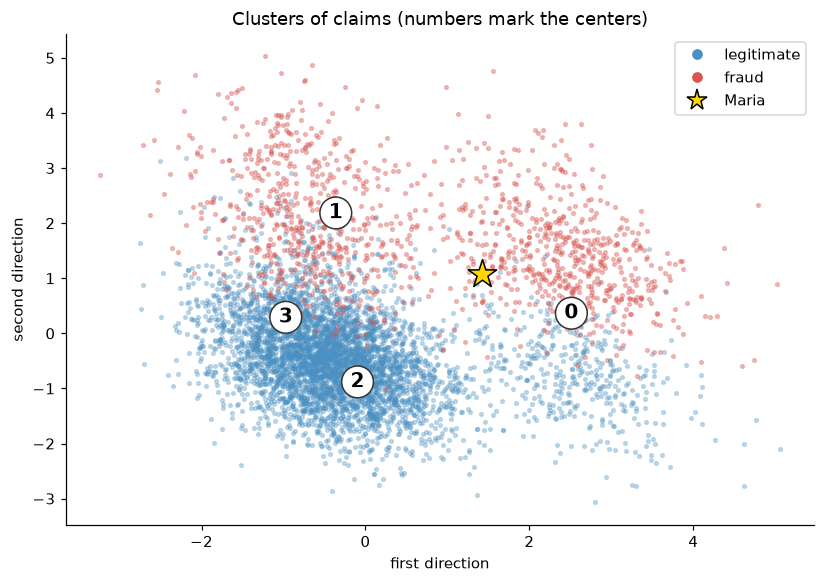

In [15]:
_, _, Vt = np.linalg.svd(Z, full_matrices=False)
P = Z @ Vt[:2].T
pm = z_maria @ Vt[:2].T

fig, ax = plt.subplots(figsize=(7.6, 5.4))
fraud_mask = claims["FraudRisk"].values == 1
ax.scatter(P[~fraud_mask, 0], P[~fraud_mask, 1], s=6, alpha=0.30, color="#4a90c2", label="legitimate")
ax.scatter(P[fraud_mask, 0], P[fraud_mask, 1], s=6, alpha=0.35, color="#d9534f", label="fraud")
cp = centers @ Vt[:2].T
for j in range(len(cp)):
    ax.text(cp[j, 0], cp[j, 1], str(j), fontsize=13, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="circle", fc="white", ec="#333"))
ax.scatter(*pm, marker="*", s=380, color="gold", edgecolor="black", zorder=5, label="Maria")
ax.set_xlabel("first direction"); ax.set_ylabel("second direction")
ax.set_title("Clusters of claims (numbers mark the centers)")
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="", color="#4a90c2", markersize=6, label="legitimate"),
           Line2D([], [], marker="o", ls="", color="#d9534f", markersize=6, label="fraud"),
           Line2D([], [], marker="*", ls="", color="gold", markeredgecolor="black", markersize=14, label="Maria")]
ax.legend(handles=handles); plt.tight_layout(); plt.show()

> **Narrate:** A picture of the groups. Five numbers do not fit on a page, so we squeeze them into two, using a method called principal components. The star is Maria. She sits in the group of claimants with prior claims, which is 936 claims, 57% of them fraud. The picture is a squeezed view, so groups overlap on the page more than they do in the numbers.
>
> **Tool:** `numpy` (a singular value decomposition) and `matplotlib` for the drawing.

A note on the picture: it squeezes five numbers into two, so groups overlap, and Maria's star appears between the prior-claims group and the suspicious-timing group. In all five numbers she is closest to the center of the prior-claims group, which is where the table puts her.

**What clustering can and cannot say.** Maria's group is about half fraud, so a group label alone would send her to review, and it would be wrong for her. Clusters describe **what claims look like**. They do not say **why** a claim is in a group, or what would happen if a claim changed. They are a rung 1 summary, as useful and as limited as the look-alike search.

### The same groups, read as customer segments
In CRM, a cluster of similar customers is a **segment**: a group that can be treated differently. We attach the customer records to the clusters and read the groups as customers instead of claims.

> **Narrate:** Now read the same groups as customers. In CRM language, a group of similar customers is a segment. We bring in the customer table and ask, for each segment, how many were flagged, how long they waited, and how many renewed. Maria's segment has many flags, long waits, and a renewal rate of 57%. That is a pattern. It is not yet a reason. We will chase the reason in Part 8.
>
> **Tool:** `pandas` `groupby`, which is the Python version of SQL's `GROUP BY`. You will see the SQL version in Part 6.

In [16]:
cust = (claims[["ClaimID", "Cluster", "Shop", "Area", "FraudRisk"]]
        .assign(Flagged=claims["Flagged"].astype(int).values)
        .merge(customers, on="ClaimID"))

segments = cust.groupby("Cluster").agg(
    customers=("ClaimID", "size"),
    flagged_pct=("Flagged", lambda s: 100 * s.mean()),
    avg_tenure_yrs=("Tenure", "mean"),
    avg_premium=("Premium", "mean"),
    avg_days_to_settle=("WaitDays", "mean"),
    renewed_pct=("Renewed", lambda s: 100 * s.mean()))
segments["maria_here"] = ["<-- Maria" if c == maria_cluster else "" for c in segments.index]
segments

,customers,flagged_pct,avg_tenure_yrs,avg_premium,avg_days_to_settle,renewed_pct,maria_here
Cluster,,,,,,,
0,936,56.838,3.845,"1,286.442",13.902,56.731,<-- Maria
1,599,58.598,3.969,"1,290.790",14.264,68.781,
2,2517,0.000,3.942,"1,277.311",5.982,82.876,
3,1948,11.704,3.996,"1,280.188",7.683,81.109,


**Reading the segments.** Tenure and premium look much the same in every group, so they do not separate customers here. Two columns do. The groups where many claims are flagged **wait longer for their claim to settle**, and they **renew less often**. Maria's segment is one of them.

This is a **rung 1** finding, and it is useful for planning: it tells the insurer which customers to look after. It does not say that the flag *causes* the lower renewal. The people in the flagged groups also differ in other ways (they have prior claims, for example), and sorting out which difference does the damage is a rung 2 question. We come back to it in Part 8.

In [17]:
note("4", "Which group am I in?", "k-means segments", "1",
     f"Group {maria_cluster}: {int(summary.loc[maria_cluster, 'claims'])} claims, {100 * summary.loc[maria_cluster, 'fraud_share']:.0f}% fraud; "
     f"{segments.loc[maria_cluster, 'renewed_pct']:.0f}% of its customers renewed.")

<details open>
<summary><b>Go further on your own: Part 4</b></summary>

- **Read:** the k-means section of the scikit-learn guide (https://scikit-learn.org/stable/modules/clustering.html#k-means). Compare its description with the loop we wrote.
- **Try:** change the number of groups from 4 to 3 and to 6. Does Maria's group stay recognizable? What happens to its fraud share?
- **Think:** how would you decide how many groups to use? There is no single right answer. What would a business reader need from the groups?
</details>

## Part 5: The knowledge graph: Maria's network (rung 1)

> **Narrate:** Maria is not alone in the files. Her claim shares a repair shop, a district and an adjuster with thousands of other claims. Draw those connections as a web, and you can ask questions by following the lines: who else went to her shop? Who else did her adjuster handle? We build the web twice, once in memory and once in Neo4j, and ask the same questions in Cypher. At the end of this part we stop and look at everything we know about Maria so far.

> **Concept:** A **knowledge graph** stores things (nodes) and the relationships between them (edges). A table answers "what is in this row?" A graph answers "who is connected to whom, and how?" **Cypher** is a language for asking graph questions by drawing the pattern you want.

So far each claim has stood alone. But claims are connected: they share **shops**, **areas** and **adjusters**. A **knowledge graph** records those connections directly, as nodes and edges, so we can ask questions that follow them.

| Node type | Examples |
|---|---|
| Claim | C0000, C0001, ..., Maria |
| Shop | Apex Auto Body, Bayview Collision, ... |
| Area | Riverside, Northgate |
| Adjuster | Adjuster 1, ..., Adjuster 6 |

| Edge | Meaning |
|---|---|
| Claim → Shop (`REPAIRED_AT`) | The shop that wrote the estimate |
| Claim → Area (`IN_AREA`) | Where the loss occurred |
| Claim → Adjuster (`HANDLED_BY`) | Who handled the claim |

### Build it in NetworkX (hand-built)

> **Narrate:** Claims do not live alone. Each one goes to a shop, comes from an area, and is handled by an adjuster. Draw those links and you have a network. We build it first in memory, where we can see every piece, with one dot for each claim, shop, area and adjuster, and a line for each link. In total that is 6,013 dots and 18,000 lines.
>
> **Tool:** `networkx`, a Python library for graphs. It needs no server. It is how we first look at a graph before deciding whether it deserves a database.

In [18]:
G = nx.Graph()
for r in claims.itertuples():
    G.add_node(r.ClaimID, kind="Claim", fraud=int(r.FraudRisk))
    G.add_edge(r.ClaimID, r.Shop, rel="REPAIRED_AT")
    G.add_edge(r.ClaimID, r.Area, rel="IN_AREA")
    G.add_edge(r.ClaimID, r.Adjuster, rel="HANDLED_BY")
for n in SHOPS: G.nodes[n]["kind"] = "Shop"
for n in AREAS: G.nodes[n]["kind"] = "Area"
for n in sorted(claims["Adjuster"].unique()): G.nodes[n]["kind"] = "Adjuster"

kinds = pd.Series({n: d["kind"] for n, d in G.nodes(data=True)}).value_counts()
print(f"{G.number_of_nodes():,} nodes and {G.number_of_edges():,} edges")
print(kinds.to_string())

6,013 nodes and 18,000 edges
Claim       6000
Adjuster       6
Shop           5
Area           2


### Ask it a question: how risky is each shop?
In a graph, "claims at a shop" means **follow the edges** from the shop node to its claim neighbors.

In [19]:
def neighbors_of_kind(graph, node, kind):
    return [n for n in graph[node] if graph.nodes[n]["kind"] == kind]

def group_table(graph, kind):
    rows = []
    for node in [n for n, d in graph.nodes(data=True) if d["kind"] == kind]:
        cl = neighbors_of_kind(graph, node, "Claim")
        rows.append((node, len(cl), 100 * np.mean([graph.nodes[c]["fraud"] for c in cl])))
    return pd.DataFrame(rows, columns=[kind.lower(), "claims", "fraud_pct"]).sort_values("fraud_pct", ascending=False).reset_index(drop=True)

shop_table = group_table(G, "Shop")
shop_table

,shop,claims,fraud_pct
0,Apex Auto Body,367,85.559
1,Bayview Collision,1126,26.377
2,Crescent Repair,1551,15.023
3,Delta Motors,1542,13.424
4,Eastside Auto,1414,12.730


**Two shops stand out.** **Apex Auto Body** has a very high share of fraudulent claims. **Bayview Collision** is also well above the others, and it is the shop on Maria's claim. Compare the areas and the adjusters:

In [20]:
print(group_table(G, "Area").to_string(index=False))
print()
print(group_table(G, "Adjuster").to_string(index=False))

     area  claims  fraud_pct
Riverside    1494     33.333
Northgate    4506     16.267

  adjuster  claims  fraud_pct
Adjuster 6     976     23.156
Adjuster 5    1015     20.788
Adjuster 1    1016     20.276
Adjuster 3    1018     20.236
Adjuster 4    1001     19.481
Adjuster 2     974     19.199


Riverside has about twice the fraud share of Northgate. The six adjusters all sit in a narrow band. Their differences are small enough that chance could produce them, so nothing here gives us a reason to act on the adjusters. A node can be well connected without being risky.

### The same graph in Neo4j
NetworkX holds the graph in memory, and it disappears when the notebook closes. A **graph database** like Neo4j stores it, and lets you ask questions in a query language, **Cypher**. A Cypher query draws the pattern you want with parentheses for nodes and arrows for edges:

```
(c:Claim)-[:REPAIRED_AT]->(s:Shop)       a claim connected to a shop
```

The next cell loads this quarter's claims into your local Neo4j. It also loads the customers and their interaction logs. **It deletes every node carrying one of the labels Claim, Shop, Area, Adjuster, Customer or Interaction**, so other graphs in the same database (such as the Bob and Alice demo) are left alone *unless they use those same labels*. If your own data uses one of those labels, use a separate Neo4j database or rename the labels before you run the cell.

<details open>
<summary><b>Dig deeper: reading the Cypher in the next cells</b></summary>

| Piece | What it does |
|---|---|
| `MATCH (c:Claim)-[:REPAIRED_AT]->(s:Shop)` | Find every pattern of a claim pointing to a shop. Parentheses are nodes, the arrow is an edge, and the word after the colon is the label or relationship type. |
| `MERGE` | Create the node or edge only if it does not already exist. Used so that five shops do not become 6,000. |
| `CREATE` | Always create a new node or edge. |
| `UNWIND $rows AS row` | Turn a list sent from Python into one row at a time, so thousands of claims load in a few batches. |
| `RETURN ... count(c), avg(c.fraud)` | Group by whatever else is returned and compute totals, as SQL's `GROUP BY` does. |
| `CREATE CONSTRAINT ... REQUIRE c.id IS UNIQUE` | Refuse a second claim with the same id, and make lookups by id fast. |
</details>

> **Narrate:** Now the same network in a real graph database. In Neo4j, a connection is not something you calculate by joining tables. It is stored as a direct link between two things, so following it is quick. We load claims, shops, areas, adjusters, customers and interactions, and then we ask questions by drawing the pattern we want, in a language called Cypher. If Neo4j is not running on your machine, these cells say so and skip, and the NetworkX answers above stand in.
>
> **Tool:** `neo4j` (the Python driver) talking to a local Neo4j server. Why a graph database? Because the questions that matter here are about connections: who shares a shop with Maria, who shares an adjuster, and who shares both.

In [21]:
CREATE_CLAIMS = '''
UNWIND $rows AS row
CREATE (:Claim {id: row.id, fraud: row.fraud, prior: row.prior, timing: row.timing, docs: row.docs,
                receipts: row.receipts, witness: row.witness, flagged: row.flagged, score: row.score,
                shop: row.shop, area: row.area, adjuster: row.adjuster})
'''
LINK_QUERIES = [
    "MATCH (c:Claim) MERGE (s:Shop {name: c.shop}) MERGE (c)-[:REPAIRED_AT]->(s)",
    "MATCH (c:Claim) MERGE (a:Area {name: c.area}) MERGE (c)-[:IN_AREA]->(a)",
    "MATCH (c:Claim) MERGE (j:Adjuster {name: c.adjuster}) MERGE (c)-[:HANDLED_BY]->(j)",
    "MATCH (c:Claim) REMOVE c.shop, c.area, c.adjuster",
]

if NEO4J_OK:
    run_cypher("MATCH (n) WHERE n:Claim OR n:Shop OR n:Area OR n:Adjuster OR n:Customer OR n:Interaction DETACH DELETE n")
    run_cypher("CREATE CONSTRAINT claim_id IF NOT EXISTS FOR (c:Claim) REQUIRE c.id IS UNIQUE")
    neo = claims.rename(columns={"ClaimID": "id", "FraudRisk": "fraud", "PriorClaims": "prior", "SuspiciousTiming": "timing",
                                 "Docs": "docs", "Receipts": "receipts", "Witness": "witness",
                                 "Shop": "shop", "Area": "area", "Adjuster": "adjuster",
                                 "Flagged": "flagged", "Score": "score"})
    neo["flagged"] = neo["flagged"].astype(int)
    neo = neo[["id", "fraud", "prior", "timing", "docs", "receipts", "witness", "flagged", "score", "shop", "area", "adjuster"]]
    rows = json.loads(neo.to_json(orient="records"))
    for i in range(0, len(rows), 1000):
        run_cypher(CREATE_CLAIMS, rows=rows[i:i + 1000])
    for q_ in LINK_QUERIES:
        run_cypher(q_)
    counts = run_cypher("MATCH (n) WHERE n:Claim OR n:Shop OR n:Area OR n:Adjuster RETURN labels(n)[0] AS label, count(n) AS nodes ORDER BY label")
    print(pd.DataFrame(counts).to_string(index=False))
else:
    print("Neo4j not connected: skipped. Nothing was loaded.")

   label  nodes
Adjuster      6
    Area      2
   Claim   6000
    Shop      5


**Customers and interactions go in as nodes too.** Each customer is linked to the claim they filed, and each interaction is linked to its claim. That is what makes the graph a relationship map: from one customer you can walk to their claim, their shop, their area, their adjuster and every contact we have had with them.

| New node | Edge |
|---|---|
| Customer | `(:Customer)-[:FILED]->(:Claim)` |
| Interaction | `(:Claim)-[:HAS_INTERACTION]->(:Interaction)` |

In [22]:
CREATE_CUSTOMERS = '''
UNWIND $rows AS row
MATCH (c:Claim {id: row.claim})
CREATE (cu:Customer {id: row.id, tenure: row.tenure, premium: row.premium, renewed: row.renewed})
CREATE (cu)-[:FILED]->(c)
'''
CREATE_INTERACTIONS = '''
UNWIND $rows AS row
MATCH (c:Claim {id: row.claim})
CREATE (c)-[:HAS_INTERACTION]->(:Interaction {type: row.type, day: row.day})
'''

if NEO4J_OK:
    quarter = customers[customers["ClaimID"] != "Maria"]
    cust_rows = json.loads(quarter.rename(columns={"CustomerID": "id", "ClaimID": "claim", "Tenure": "tenure",
                                                   "Premium": "premium", "Renewed": "renewed"})
                           [["id", "claim", "tenure", "premium", "renewed"]].to_json(orient="records"))
    for i in range(0, len(cust_rows), 1000):
        run_cypher(CREATE_CUSTOMERS, rows=cust_rows[i:i + 1000])
    int_rows = json.loads(interactions[interactions["ClaimID"] != "Maria"]
                          .rename(columns={"ClaimID": "claim", "Interaction": "type", "Day": "day"}).to_json(orient="records"))
    for i in range(0, len(int_rows), 5000):
        run_cypher(CREATE_INTERACTIONS, rows=int_rows[i:i + 5000])
    counts = run_cypher("MATCH (n) WHERE n:Claim OR n:Customer OR n:Interaction RETURN labels(n)[0] AS label, count(n) AS nodes ORDER BY label")
    print(pd.DataFrame(counts).to_string(index=False))
else:
    print("Neo4j not connected: skipped. Nothing was loaded.")

      label  nodes
      Claim   6000
   Customer   6000
Interaction  20222


**The same question in Cypher: how risky is each shop?** Read it like a sentence: *match every claim that was repaired at a shop; for each shop, return the number of claims and the fraud share.*

In [23]:
CYPHER_SHOPS = '''
MATCH (c:Claim)-[:REPAIRED_AT]->(s:Shop)
RETURN s.name AS shop, count(c) AS claims, round(100.0 * avg(c.fraud), 1) AS fraud_pct
ORDER BY fraud_pct DESC
'''
neo_shops = show_cypher(CYPHER_SHOPS)
neo_shops

MATCH (c:Claim)-[:REPAIRED_AT]->(s:Shop)
RETURN s.name AS shop, count(c) AS claims, round(100.0 * avg(c.fraud), 1) AS fraud_pct
ORDER BY fraud_pct DESC


,shop,claims,fraud_pct
0,Apex Auto Body,367,85.600
1,Bayview Collision,1126,26.400
2,Crescent Repair,1551,15.000
3,Delta Motors,1542,13.400
4,Eastside Auto,1414,12.700


> **Narrate:** The same question we asked NetworkX, now in Cypher: how risky is each shop? Read the query like a sentence: match every claim that was repaired at a shop, then return each shop's name, how many claims it had, and what share were fraud. The answer matches the in-memory one, and the notebook checks that for you. Two tools, one answer. Apex has an extremely high share, and Bayview is clearly above the others.

In [24]:
if NEO4J_OK:
    same = (neo_shops.sort_values("shop").reset_index(drop=True)["claims"].tolist()
            == shop_table.sort_values("shop").reset_index(drop=True)["claims"].tolist())
    print("Neo4j and NetworkX agree on the claim counts:", same)

Neo4j and NetworkX agree on the claim counts: True


**A pattern across two hops: shop and area together.** This one follows two edges from each claim.

In [25]:
CYPHER_SHOP_AREA = '''
MATCH (c:Claim)-[:IN_AREA]->(a:Area), (c)-[:REPAIRED_AT]->(s:Shop)
RETURN a.name AS area, s.name AS shop, count(c) AS claims, round(100.0 * avg(c.fraud), 1) AS fraud_pct
ORDER BY area, shop
'''
show_cypher(CYPHER_SHOP_AREA)

MATCH (c:Claim)-[:IN_AREA]->(a:Area), (c)-[:REPAIRED_AT]->(s:Shop)
RETURN a.name AS area, s.name AS shop, count(c) AS claims, round(100.0 * avg(c.fraud), 1) AS fraud_pct
ORDER BY area, shop


,area,shop,claims,fraud_pct
0,Northgate,Apex Auto Body,273,86.100
1,Northgate,Bayview Collision,241,10.800
2,Northgate,Crescent Repair,1375,12.400
3,Northgate,Delta Motors,1368,12.000
4,Northgate,Eastside Auto,1249,11.000
5,Riverside,Apex Auto Body,94,84.000
6,Riverside,Bayview Collision,885,30.600
7,Riverside,Crescent Repair,176,35.200
8,Riverside,Delta Motors,174,24.700
9,Riverside,Eastside Auto,165,26.100


In [26]:
shop_area = (claims.groupby(["Area", "Shop"]).agg(claims=("ClaimID", "size"), fraud_pct=("FraudRisk", lambda s: 100 * s.mean()))
             .reset_index())
shop_area

,Area,Shop,claims,fraud_pct
0,Northgate,Apex Auto Body,273,86.081
1,Northgate,Bayview Collision,241,10.788
2,Northgate,Crescent Repair,1375,12.436
3,Northgate,Delta Motors,1368,11.988
4,Northgate,Eastside Auto,1249,10.969
5,Riverside,Apex Auto Body,94,84.043
6,Riverside,Bayview Collision,885,30.621
7,Riverside,Crescent Repair,176,35.227
8,Riverside,Delta Motors,174,24.713
9,Riverside,Eastside Auto,165,26.061


### Add Maria to the graph and look at her neighborhood
Maria's claim joins the graph as one more node, connected to her shop, her area and her adjuster. Then we ask for the **facts** about her claim, the same way the earlier graph RAG demo retrieved facts about a person.

> **Narrate:** Maria joins the network. One new claim node, with three links: to her shop, to her area, and to her adjuster. Now we can ask what is around her. Bayview Collision, her shop, has 1,126 other claims, and 26% of them were fraud. Her area, Riverside, is 33% fraud, twice as high as Northgate. Each of these is a connection. None is yet a reason.

In [27]:
G.add_node("Maria", kind="Claim", fraud=0)
G.add_edge("Maria", "Bayview Collision", rel="REPAIRED_AT")
G.add_edge("Maria", "Riverside", rel="IN_AREA")
G.add_edge("Maria", "Adjuster 3", rel="HANDLED_BY")

maria_facts = [("Maria", G.edges["Maria", n]["rel"], n) for n in G["Maria"]]
print("Facts about Maria's claim (NetworkX):")
for s_, p_, o_ in maria_facts: print(f"  {s_} -{p_}-> {o_}")

peers = [c for c in neighbors_of_kind(G, "Bayview Collision", "Claim") if c != "Maria"]
peer_fraud = 100 * np.mean([G.nodes[c]["fraud"] for c in peers])
print(f"\nOther claims at Bayview Collision: {len(peers):,}, of which {peer_fraud:.1f}% were fraud")
note("5", "How am I connected?", "Knowledge graph, Neo4j, Cypher", "1",
     f"Her shop, Bayview Collision, has {len(peers):,} other claims, {peer_fraud:.0f}% fraud. Her area, Riverside, is {group_table(G, 'Area').set_index('area').loc['Riverside', 'fraud_pct']:.0f}% fraud.")

Facts about Maria's claim (NetworkX):
  Maria -REPAIRED_AT-> Bayview Collision
  Maria -IN_AREA-> Riverside
  Maria -HANDLED_BY-> Adjuster 3

Other claims at Bayview Collision: 1,126, of which 26.4% were fraud


In [28]:
ADD_MARIA = '''
MATCH (s:Shop {name: $shop}), (a:Area {name: $area}), (j:Adjuster {name: $adjuster})
CREATE (m:Claim {id: 'Maria', fraud: 0, prior: 1, timing: 0, docs: 4.5, receipts: 3.6, witness: 3.0, flagged: 1, score: $score})
CREATE (m)-[:REPAIRED_AT]->(s)
CREATE (m)-[:IN_AREA]->(a)
CREATE (m)-[:HANDLED_BY]->(j)
'''
CYPHER_MARIA_FACTS = '''
MATCH (m:Claim {id: 'Maria'})-[r]->(x)
WHERE x:Shop OR x:Area OR x:Adjuster
RETURN type(r) AS predicate, x.name AS object
'''
CYPHER_MARIA_PEERS = '''
MATCH (m:Claim {id: 'Maria'})-[:REPAIRED_AT]->(s:Shop)<-[:REPAIRED_AT]-(o:Claim)
WHERE o.id <> 'Maria'
RETURN s.name AS shop, count(o) AS peers, round(100.0 * avg(o.fraud), 1) AS fraud_pct
'''
if NEO4J_OK:
    run_cypher("MATCH (:Claim {id: 'Maria'})-[:HAS_INTERACTION]->(i:Interaction) DETACH DELETE i")   # safe to re-run
    run_cypher("MATCH (cu:Customer {id: 'Maria'}) DETACH DELETE cu")
    run_cypher("MATCH (m:Claim {id: 'Maria'}) DETACH DELETE m")
    run_cypher(ADD_MARIA, shop="Bayview Collision", area="Riverside", adjuster="Adjuster 3", score=float(p_maria))
show_cypher(CYPHER_MARIA_FACTS)

MATCH (m:Claim {id: 'Maria'})-[r]->(x)
WHERE x:Shop OR x:Area OR x:Adjuster
RETURN type(r) AS predicate, x.name AS object


,predicate,object
0,HANDLED_BY,Adjuster 3
1,REPAIRED_AT,Bayview Collision
2,IN_AREA,Riverside


In [29]:
show_cypher(CYPHER_MARIA_PEERS)

MATCH (m:Claim {id: 'Maria'})-[:REPAIRED_AT]->(s:Shop)<-[:REPAIRED_AT]-(o:Claim)
WHERE o.id <> 'Maria'
RETURN s.name AS shop, count(o) AS peers, round(100.0 * avg(o.fraud), 1) AS fraud_pct


,shop,peers,fraud_pct
0,Bayview Collision,1126,26.400


### Customer 360: everything about Maria in one place
A **customer 360** is one view of everything the insurer knows about one customer: who she is, what she filed, who handled it, and every contact since. In a spreadsheet world that means stitching several files together. In a graph it is one walk outward from the customer. First the same view built from our tables, then the Cypher version.

> **Narrate:** A customer 360 is one view of everything we know about a person: the profile, the claim, her shop, her segment, and a timeline. For Maria it reads: six years with the company, a model score of 0.964, a claim sent to fraud review on day 3, a document request on day 5, settled on day 22, and lapsed on day 67. Read that timeline slowly. It is the whole story in five lines, and the second line is the one the insurer did to her.

In [30]:
def customer_360(claim_id):
    cu = customers[customers["ClaimID"] == claim_id].iloc[0]
    if claim_id == "Maria":
        info = dict(Shop="Bayview Collision", Area="Riverside", Adjuster="Adjuster 3", PriorClaims=1,
                    Score=p_maria, Cluster=maria_cluster)
    else:
        info = claims[claims["ClaimID"] == claim_id].iloc[0].to_dict()
        info["Cluster"] = int(cust.loc[cust["ClaimID"] == claim_id, "Cluster"].iloc[0])
    seg = cust[cust["Cluster"] == info["Cluster"]]
    shop_peers = cust[(cust["Shop"] == info["Shop"]) & (cust["ClaimID"] != claim_id)]
    log = interactions[interactions["ClaimID"] == claim_id].sort_values("Day")
    print(f"CUSTOMER 360: {claim_id}")
    print("-" * 70)
    print(f"Profile:   {cu.Tenure:.1f} years with us, annual premium ${cu.Premium:,.0f}, {int(info['PriorClaims'])} earlier claim(s)")
    print(f"Claim:     repaired at {info['Shop']}, loss in {info['Area']}, handled by {info['Adjuster']}, model score {info['Score']:.3f}")
    print(f"Segment:   group {info['Cluster']}, {len(seg):,} customers, {100 * seg['Renewed'].mean():.0f}% of them renewed")
    print(f"Shop:      {len(shop_peers):,} other {info['Shop']} customers, {100 * shop_peers['Renewed'].mean():.0f}% renewed")
    print("Timeline:  " + "  ->  ".join(f"day {int(d)}: {w}" for w, d in zip(log["Interaction"], log["Day"])))

customer_360("Maria")

CUSTOMER 360: Maria
----------------------------------------------------------------------
Profile:   6.0 years with us, annual premium $1,350, 1 earlier claim(s)
Claim:     repaired at Bayview Collision, loss in Riverside, handled by Adjuster 3, model score 0.964
Segment:   group 0, 936 customers, 57% of them renewed
Shop:      1,126 other Bayview Collision customers, 73% renewed
Timeline:  day 0: Claim filed  ->  day 3: Sent to fraud review  ->  day 5: Document request  ->  day 22: Claim settled  ->  day 67: Lapsed


In [31]:
ADD_MARIA_CRM = '''
MATCH (m:Claim {id: 'Maria'})
CREATE (cu:Customer {id: 'Maria', tenure: $tenure, premium: $premium, renewed: $renewed})
CREATE (cu)-[:FILED]->(m)
WITH m
UNWIND $events AS e
CREATE (m)-[:HAS_INTERACTION]->(:Interaction {type: e.type, day: e.day})
'''
CYPHER_360_PROFILE = '''
MATCH (cu:Customer)-[:FILED]->(m:Claim {id: 'Maria'})-[:REPAIRED_AT]->(s:Shop),
      (m)-[:IN_AREA]->(a:Area), (m)-[:HANDLED_BY]->(j:Adjuster)
RETURN cu.tenure AS tenure_years, cu.premium AS premium, cu.renewed AS renewed,
       m.flagged AS flagged, round(m.score, 3) AS score, s.name AS shop, a.name AS area, j.name AS adjuster
'''
CYPHER_360_TIMELINE = '''
MATCH (:Claim {id: 'Maria'})-[:HAS_INTERACTION]->(i:Interaction)
RETURN i.day AS day, i.type AS interaction
ORDER BY day
'''
if NEO4J_OK:
    run_cypher(ADD_MARIA_CRM, tenure=maria_crm["Tenure"], premium=maria_crm["Premium"], renewed=maria_crm["Renewed"],
               events=[{"type": w_, "day": d_} for w_, d_ in maria_events])
show_cypher(CYPHER_360_PROFILE)

MATCH (cu:Customer)-[:FILED]->(m:Claim {id: 'Maria'})-[:REPAIRED_AT]->(s:Shop),
      (m)-[:IN_AREA]->(a:Area), (m)-[:HANDLED_BY]->(j:Adjuster)
RETURN cu.tenure AS tenure_years, cu.premium AS premium, cu.renewed AS renewed,
       m.flagged AS flagged, round(m.score, 3) AS score, s.name AS shop, a.name AS area, j.name AS adjuster


,tenure_years,premium,renewed,flagged,score,shop,area,adjuster
0,6.000,"1,350.000",0,1,0.964,Bayview Collision,Riverside,Adjuster 3


In [32]:
show_cypher(CYPHER_360_TIMELINE)

MATCH (:Claim {id: 'Maria'})-[:HAS_INTERACTION]->(i:Interaction)
RETURN i.day AS day, i.type AS interaction
ORDER BY day


,day,interaction
0,0,Claim filed
1,3,Sent to fraud review
2,5,Document request
3,22,Claim settled
4,67,Lapsed


**A retention question in Cypher.** Among customers whose claim was **legitimate**, compare renewal for those who were flagged with those who were not. This is a rung 1 comparison, read straight from the graph.

In [33]:
CYPHER_RETENTION = '''
MATCH (cu:Customer)-[:FILED]->(c:Claim)
WHERE c.fraud = 0 AND c.id <> 'Maria'
RETURN c.flagged AS flagged, count(cu) AS customers, round(100.0 * avg(cu.renewed), 1) AS renewed_pct
ORDER BY flagged
'''
neo_ret = show_cypher(CYPHER_RETENTION)
neo_ret

MATCH (cu:Customer)-[:FILED]->(c:Claim)
WHERE c.fraud = 0 AND c.id <> 'Maria'
RETURN c.flagged AS flagged, count(cu) AS customers, round(100.0 * avg(cu.renewed), 1) AS renewed_pct
ORDER BY flagged


,flagged,customers,renewed_pct
0,0,4692,81.800
1,1,77,50.600


In [34]:
honest_q = cust[cust["FraudRisk"] == 0]
(honest_q.groupby("Flagged").agg(customers=("ClaimID", "size"), renewed_pct=("Renewed", lambda s: 100 * s.mean()))
         .reset_index())

,Flagged,customers,renewed_pct
0,0,4692,81.820
1,1,77,50.649


Honest customers who were flagged renewed less often than honest customers who were not. How much of that gap is *caused by the flag*? The graph cannot say. We answer that in Part 8.

### The picture
Each shop is placed next to the area its claims come from. A thicker line means more claims, and darker red means a higher fraud share.

> **Narrate:** One picture of the whole network, with each shop colored by how risky it looks. The picture invites a conclusion: Bayview looks like the problem. We are about to test that conclusion instead of believing it.
>
> **Tool:** `networkx` for the layout and `matplotlib` for the drawing.

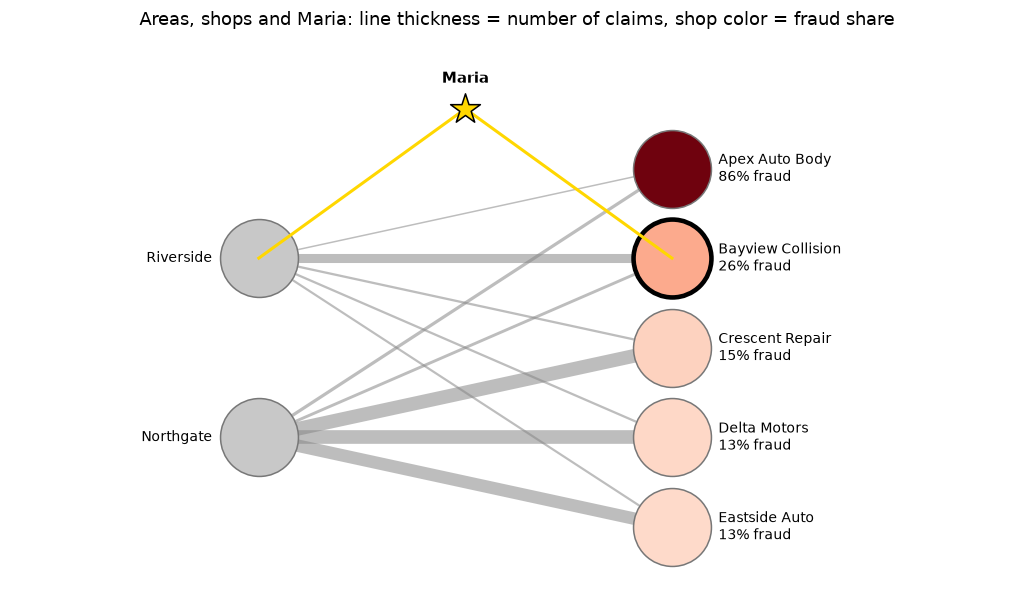

In [35]:
import matplotlib.colors as mcolors
cm = plt.cm.Reds
fig, ax = plt.subplots(figsize=(9.5, 5.6))
area_pos = {"Riverside": (0, 1.2), "Northgate": (0, -1.2)}
shop_pos = {s: (4, y) for s, y in zip(SHOPS, [2.4, 1.2, 0, -1.2, -2.4])}
share = shop_table.set_index("shop")["fraud_pct"]
cnt = shop_area.set_index(["Area", "Shop"])["claims"]
for (a, s), n in cnt.items():
    ax.plot([area_pos[a][0], shop_pos[s][0]], [area_pos[a][1], shop_pos[s][1]], color="#888", lw=0.4 + n / 160, alpha=0.55, zorder=1)
for s, (x, y) in shop_pos.items():
    ax.scatter(x, y, s=2600, color=cm(share[s] / 100 * 1.15), edgecolor="black" if s == "Bayview Collision" else "#777",
               linewidth=3 if s == "Bayview Collision" else 1, zorder=2)
    ax.text(x + 0.45, y, f"{s}\n{share[s]:.0f}% fraud", va="center", fontsize=9)
for a, (x, y) in area_pos.items():
    ax.scatter(x, y, s=2600, color="#c8c8c8", edgecolor="#777", zorder=2)
    ax.text(x - 0.45, y, a, va="center", ha="right", fontsize=9)
mx, my = 2.0, 3.2
ax.scatter(mx, my, marker="*", s=420, color="gold", edgecolor="black", zorder=4)
ax.text(mx, my + 0.35, "Maria", ha="center", fontsize=10, weight="bold")
ax.plot([mx, area_pos["Riverside"][0]], [my, area_pos["Riverside"][1]], color="gold", lw=2, zorder=3)
ax.plot([mx, shop_pos["Bayview Collision"][0]], [my, shop_pos["Bayview Collision"][1]], color="gold", lw=2, zorder=3)
ax.set_xlim(-2.4, 7.4); ax.set_ylim(-3.3, 4.2); ax.axis("off")
ax.set_title("Areas, shops and Maria: line thickness = number of claims, shop color = fraud share")
plt.tight_layout(); plt.show()

### What the graph says, and what we are tempted to conclude
Two shops stand out, and Maria is attached to one of them. It is tempting to write two **hypotheses** straight from the picture:

- **H1:** Claims at **Bayview Collision** are fraud-prone *because of the shop*.
- **H2:** Claims at **Apex Auto Body** are fraud-prone *because of the shop*.

Both are rung 1 patterns so far: a shop and fraud go together. Nothing here says that **changing** what happens at either shop would change the fraud. That is a rung 2 question, and we test it in Part 7.

### Checkpoint: what we know about Maria so far
> **Narrate:** Let us stop and take stock. Five tools gave us five answers. Read the last column and notice that every answer is the same kind of answer: things that go together. None of them says why.

In [36]:
show_ledger("WHAT WE KNOW ABOUT MARIA SO FAR (every row is rung 1: what goes with what)")

WHAT WE KNOW ABOUT MARIA SO FAR (every row is rung 1: what goes with what)


Part,Maria asks,Tool,Rung,What we found
1,Why was I flagged?,Logistic regression,1,"Score 0.96, above the 0.5 cut-off. The review found her claim legitimate: a false positive."
2,What is in the files about me?,"Tables: claims, customers, interactions",1,"6,001 customers and 20,227 logged contacts. Maria: 6 years, $1,350 a year, 22-day wait, lapsed."
3,Who else looks like me?,"TF-IDF cosine, ChromaDB",1,"Of the 25 notes closest to hers, 96% were fraud (overall: 21%). Look-alikes point the wrong way."
4,Which group am I in?,k-means segments,1,"Group 0: 936 claims, 57% fraud; 57% of its customers renewed."
5,How am I connected?,"Knowledge graph, Neo4j, Cypher",1,"Her shop, Bayview Collision, has 1,126 other claims, 26% fraud. Her area, Riverside, is 33% fraud."


<details open>
<summary><b>Go further on your own: Part 5</b></summary>

- **Read:** the Cypher manual's "Patterns" chapter (https://neo4j.com/docs/cypher-manual/current/) and the NetworkX tutorial (https://networkx.org/documentation/stable/tutorial.html).
- **Try:** in Neo4j Browser, run `MATCH (m:Claim {id: 'Maria'})-[r]->(x) RETURN m, r, x` and look at the picture it draws.
- **Try:** write a Cypher query for the adjusters who handled more than 1,000 claims.
- **Think:** which question in this part could you not answer from a single table without a join? Which could you answer from either?
</details>

## Part 6: Three stores, one Maria

> **Narrate:** By now Maria's information lives in three places. A relational database holds her records in tables. A graph database holds her connections. A vector database holds what her note says. Each store is good at a different kind of question. So let us put one question to each, about Maria, and watch what each is built to do well.

> **Concept:** There is no best database, only a best match between the **question** and the **store**.

| Store | Built for | Typical question | Language |
|---|---|---|---|
| **Relational (SQL)** | Totals, filters and joins across tables of records | "What share of honest customers at each shop renewed?" | SQL |
| **Graph (Neo4j)** | Following connections, several hops at a time | "Who shares both Maria's shop and her adjuster?" | Cypher |
| **Vector (ChromaDB)** | Finding the closest items by meaning or wording | "Which notes read most like Maria's?" | A query vector, plus optional filters |

The relational store here is **SQLite**, which ships with Python and keeps the whole database in one file (`data/claims_crm.sqlite`), so there is nothing to install. The next cell copies the tables we already have into it.

<details open>
<summary><b>Dig deeper: what SQL is doing in the next cells</b></summary>

| Piece | What it does |
|---|---|
| `SELECT ... FROM claims` | Pick columns from a table. |
| `JOIN customers ON customers.ClaimID = claims.ClaimID` | Line up rows from two tables that share a key. |
| `WHERE FraudRisk = 0` | Keep only the rows that pass a test. |
| `GROUP BY Shop` with `COUNT(*)`, `AVG(...)` | One output row per group, with totals. |
| Self-join (`claims m JOIN claims o ON ...`) | Match a table with itself, here to find other claims that share Maria's shop and adjuster. |
</details>

> **Narrate:** Here is the third home for Maria's data, and the oldest: a relational database. Rows and columns, joined by shared keys. We copy the three tables we already have into SQLite, a database that lives in one file and needs no installation. Then we put four questions to the three stores, one at a time, and watch what each store is built to do well.
>
> **Tool:** `sqlite3`, which ships with Python. Why SQLite and not a server database? Because it removes everything that can go wrong for a student: no server, no password, one file. The SQL we write is almost identical in PostgreSQL or MySQL.

In [37]:
import sqlite3
from contextlib import closing

DB_PATH = ROOT / "data" / "claims_crm.sqlite"
DB_PATH.parent.mkdir(exist_ok=True)

maria_row = dict(ClaimID="Maria", Area="Riverside", Shop="Bayview Collision", Adjuster="Adjuster 3", PriorClaims=1, SuspiciousTiming=0,
                 Docs=4.5, FollowUp=0, Receipts=3.6, Witness=3.0, FraudRisk=0, Score=float(p_maria), Note=maria_note,
                 Flagged=1, Cluster=int(maria_cluster))
sql_claims = pd.concat([
    claims[["ClaimID", "Area", "Shop", "Adjuster", "PriorClaims", "SuspiciousTiming", "Docs", "FollowUp", "Receipts",
            "Witness", "FraudRisk", "Score", "Note"]].assign(Flagged=claims["Flagged"].astype(int).values, Cluster=claims["Cluster"].values),
    pd.DataFrame([maria_row])], ignore_index=True)

with closing(sqlite3.connect(DB_PATH)) as con:
    sql_claims.to_sql("claims", con, if_exists="replace", index=False)
    customers.to_sql("customers", con, if_exists="replace", index=False)
    interactions.to_sql("interactions", con, if_exists="replace", index=False)
    con.execute("CREATE INDEX IF NOT EXISTS idx_claims_id ON claims(ClaimID)")
    con.execute("CREATE INDEX IF NOT EXISTS idx_customers_claim ON customers(ClaimID)")
    con.execute("CREATE INDEX IF NOT EXISTS idx_interactions_claim ON interactions(ClaimID)")
    con.commit()

def sql(query, **params):
    with closing(sqlite3.connect(DB_PATH)) as con:
        return pd.read_sql_query(query, con, params=params or None)

print(f"SQLite file: {DB_PATH}")
print(sql("SELECT 'claims' AS tableName, COUNT(*) AS rows FROM claims UNION ALL SELECT 'customers', COUNT(*) FROM customers UNION ALL SELECT 'interactions', COUNT(*) FROM interactions").to_string(index=False))

SQLite file: c:\Users\Jared\OneDrive\Documents\School\INFO 5810\maria-main\data\claims_crm.sqlite
   tableName  rows
      claims  6001
   customers  6001
interactions 20227


### Question 1, for the relational store: a total across many customers
*Among customers whose claim was legitimate, what share renewed, shop by shop?* This is what SQL is for: filter, join two tables, group and total.

In [38]:
SQL_RENEWAL_BY_SHOP = '''
SELECT c.Shop,
       COUNT(*)                          AS customers,
       ROUND(100.0 * AVG(u.Renewed), 1)  AS renewed_pct
FROM claims c
JOIN customers u ON u.ClaimID = c.ClaimID
WHERE c.FraudRisk = 0 AND c.ClaimID <> 'Maria'
GROUP BY c.Shop
ORDER BY renewed_pct
'''
print(SQL_RENEWAL_BY_SHOP.strip(), "\n")
sql_by_shop = sql(SQL_RENEWAL_BY_SHOP)
print(sql_by_shop.to_string(index=False))

check = (cust[cust["FraudRisk"] == 0].groupby("Shop")["Renewed"].agg(customers="size", renewed_pct=lambda s: round(100 * s.mean(), 1)).reset_index()
         .sort_values("renewed_pct").reset_index(drop=True))
print("\nSQL agrees with the same calculation in pandas:", sql_by_shop.round(1).equals(check.round(1)))

SELECT c.Shop,
       COUNT(*)                          AS customers,
       ROUND(100.0 * AVG(u.Renewed), 1)  AS renewed_pct
FROM claims c
JOIN customers u ON u.ClaimID = c.ClaimID
WHERE c.FraudRisk = 0 AND c.ClaimID <> 'Maria'
GROUP BY c.Shop
ORDER BY renewed_pct 

             Shop  customers  renewed_pct
   Apex Auto Body         53       69.800
Bayview Collision        829       79.500
  Crescent Repair       1318       80.800
     Delta Motors       1335       82.100
    Eastside Auto       1234       82.700

SQL agrees with the same calculation in pandas: True


> **Narrate:** The first question suits SQL exactly: among customers whose claim was legitimate, what share renewed, shop by shop? Filter, join two tables, group, total. The notebook also computes the same table in pandas and confirms the two agree. So SQL and pandas are two ways of saying the same thing. Honest customers at Apex renewed least often, and at Eastside most often.

### Question 2, for the relational store: everything about one customer
*What does the insurer know about Maria?* A join stitches the customer table to the claim table through the shared claim ID, and a second query reads her contact log. This is the customer 360 again, built from tables.

In [39]:
SQL_MARIA_360 = '''
SELECT u.Tenure, u.Premium, c.Shop, c.Area, c.Adjuster, ROUND(c.Score, 3) AS Score,
       c.Flagged, u.WaitDays, u.Renewed
FROM customers u
JOIN claims c ON c.ClaimID = u.ClaimID
WHERE u.ClaimID = 'Maria'
'''
print(SQL_MARIA_360.strip(), "\n")
print(sql(SQL_MARIA_360).to_string(index=False))
print()
print(sql("SELECT Day, Interaction FROM interactions WHERE ClaimID = 'Maria' ORDER BY Day").to_string(index=False))

SELECT u.Tenure, u.Premium, c.Shop, c.Area, c.Adjuster, ROUND(c.Score, 3) AS Score,
       c.Flagged, u.WaitDays, u.Renewed
FROM customers u
JOIN claims c ON c.ClaimID = u.ClaimID
WHERE u.ClaimID = 'Maria' 

 Tenure   Premium              Shop      Area   Adjuster  Score  Flagged  WaitDays  Renewed
  6.000 1,350.000 Bayview Collision Riverside Adjuster 3  0.964        1        22        0

 Day          Interaction
   0          Claim filed
   3 Sent to fraud review
   5     Document request
  22        Claim settled
  67               Lapsed


> **Narrate:** The second question is about one person. A join stitches the customer table to the claim table through the shared claim ID, and a second query reads her contact log. It is the same customer 360 we built in Part 5, now assembled from tables. Same facts, different store.

### Question 3, for the graph store: a pattern that follows connections
*How do the other claims that share both Maria's repair shop and her adjuster look?* In the graph this is one picture: two arrows out of Maria, two arrows back in. We ask it in Cypher, then ask the same question in SQL (a self-join) and in pandas, and check that all three agree.

In [40]:
CYPHER_PEERS_TWO_HOPS = '''
MATCH (m:Claim {id: 'Maria'})-[:REPAIRED_AT]->(s:Shop)<-[:REPAIRED_AT]-(o:Claim)-[:HANDLED_BY]->(j:Adjuster)<-[:HANDLED_BY]-(m)
WHERE o.id <> 'Maria'
RETURN count(o) AS peers, round(100.0 * avg(o.fraud), 1) AS fraud_pct
'''
neo_two = show_cypher(CYPHER_PEERS_TWO_HOPS)
if neo_two is not None:
    print(neo_two.to_string(index=False))

MATCH (m:Claim {id: 'Maria'})-[:REPAIRED_AT]->(s:Shop)<-[:REPAIRED_AT]-(o:Claim)-[:HANDLED_BY]->(j:Adjuster)<-[:HANDLED_BY]-(m)
WHERE o.id <> 'Maria'
RETURN count(o) AS peers, round(100.0 * avg(o.fraud), 1) AS fraud_pct
 peers  fraud_pct
   183     27.900


In [41]:
SQL_PEERS_SELF_JOIN = '''
SELECT COUNT(*) AS peers, ROUND(100.0 * AVG(o.FraudRisk), 1) AS fraud_pct
FROM claims m
JOIN claims o ON o.Shop = m.Shop AND o.Adjuster = m.Adjuster AND o.ClaimID <> m.ClaimID
WHERE m.ClaimID = 'Maria'
'''
print(SQL_PEERS_SELF_JOIN.strip(), "\n")
sql_two = sql(SQL_PEERS_SELF_JOIN)
print(sql_two.to_string(index=False))

pd_two = claims[(claims["Shop"] == "Bayview Collision") & (claims["Adjuster"] == "Adjuster 3")]
print(f"\npandas: {len(pd_two)} peers, {100 * pd_two['FraudRisk'].mean():.1f}% fraud")
agree = len(pd_two) == int(sql_two.loc[0, "peers"]) and (neo_two is None or len(pd_two) == int(neo_two.loc[0, "peers"]))
print("All available stores agree:", agree)

SELECT COUNT(*) AS peers, ROUND(100.0 * AVG(o.FraudRisk), 1) AS fraud_pct
FROM claims m
JOIN claims o ON o.Shop = m.Shop AND o.Adjuster = m.Adjuster AND o.ClaimID <> m.ClaimID
WHERE m.ClaimID = 'Maria' 

 peers  fraud_pct
   183     27.900

pandas: 183 peers, 27.9% fraud
All available stores agree: True


> **Narrate:** The third question follows connections: how do the claims that share both Maria's shop and her adjuster look? In Cypher it is a picture, two arrows out of Maria and two arrows back in. In SQL it is a self-join, a table joined to itself. The notebook asks both and also computes it in pandas. All three give the same answer: 183 other claims, 27.9% fraud. One hop is easy in either language. Add more hops and SQL needs another join each time, while Cypher needs one more arrow.

SQL can answer this too, with a self-join, and for **one** hop it is just as short. The difference shows as the pattern grows: each extra hop is another join in SQL, while in Cypher it is one more arrow in the picture. A graph database stores each connection as a direct link, so following it does not require searching a table.

### Question 4, for the vector store: closeness in meaning or wording
*Which notes read most like Maria's, but only at her own repair shop?* The vector store ranks by similarity, and a **metadata filter** limits the search before ranking. Neither SQL nor Cypher is built to rank by "reads like".

In [42]:
filtered = notes_col.query(query_embeddings=[q.tolist()], n_results=25, where={"shop": "Bayview Collision"},
                           include=["metadatas", "documents", "distances"])
share_bay = np.mean([m["fraud"] for m in filtered["metadatas"][0]])
print("The three notes at Bayview Collision that read most like Maria's:\n")
for doc_, dist_, meta_ in list(zip(filtered["documents"][0], filtered["distances"][0], filtered["metadatas"][0]))[:3]:
    print(f"  similarity {1 - dist_:.2f}  fraud={meta_['fraud']}  {doc_}")
print(f"\nOf the 25 closest notes at Bayview, {100 * share_bay:.0f}% were fraud.")

The three notes at Bayview Collision that read most like Maria's:

  similarity 1.00  fraud=1  claimant has filed before; several receipts do not match the estimate; witness statements conflict; documentation is thin; repair estimate from Bayview Collision; loss occurred in the Riverside district.
  similarity 0.95  fraud=1  claimant has filed before; several receipts do not match the estimate; witness statements conflict; documentation is adequate; repair estimate from Bayview Collision; loss occurred in the Riverside district.
  similarity 0.95  fraud=1  claimant has filed before; several receipts do not match the estimate; witness statements conflict; documentation is adequate; repair estimate from Bayview Collision; loss occurred in the Riverside district.

Of the 25 closest notes at Bayview, 92% were fraud.


> **Narrate:** The fourth question is the one only the vector database can answer: which notes read most like Maria's, but only at her own shop? ChromaDB ranks by similarity and applies the shop filter at the same time. At Bayview, 92% of the 25 closest notes were fraud. SQL has no idea what "reads like" means, and Cypher does not either.

### Putting the three side by side

In [43]:
three = pd.DataFrame([
    ("Relational (SQL)", "Share of honest customers who renewed, by shop", "Totals across many records, joined across tables",
     f"{sql_by_shop['renewed_pct'].min():.0f}% to {sql_by_shop['renewed_pct'].max():.0f}% across shops"),
    ("Graph (Cypher)", "Claims that share Maria's shop and her adjuster", "Patterns that follow connections",
     f"{len(pd_two)} claims, {100 * pd_two['FraudRisk'].mean():.0f}% fraud"),
    ("Vector (ChromaDB)", "Notes at her shop that read like hers", "Closeness in wording or meaning, with filters",
     f"{100 * share_bay:.0f}% of the 25 closest were fraud"),
], columns=["Store", "Question we asked", "What it is built for", "Answer"])
display(three.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))
note("6", "Which store answers which question?", "SQL, Cypher, vector search", "1",
     f"Same Maria, three stores. SQL totals, Cypher follows links ({len(pd_two)} peers at her shop and adjuster), vectors rank by wording.")

Store,Question we asked,What it is built for,Answer
Relational (SQL),"Share of honest customers who renewed, by shop","Totals across many records, joined across tables",70% to 83% across shops
Graph (Cypher),Claims that share Maria's shop and her adjuster,Patterns that follow connections,"183 claims, 28% fraud"
Vector (ChromaDB),Notes at her shop that read like hers,"Closeness in wording or meaning, with filters",92% of the 25 closest were fraud


> **Narrate:** Side by side: SQL for totals across many records, Cypher for patterns that follow connections, vectors for closeness in wording. None of them tells us why Maria was flagged, or whether her shop is to blame. Every answer so far is a pattern. To learn more, we have to stop watching and start acting.

> **Narrate:** Three stores, three kinds of question, one Maria. None of them says why she was flagged, or whether her shop is to blame. They only tell us what goes with what. To go further we have to climb from the first rung of the ladder (seeing) to the second (doing), and ask what would happen if we **acted**.

<details open>
<summary><b>Go further on your own: Part 6</b></summary>

- **Read:** the SQLite documentation (https://www.sqlite.org/docs.html) and Python's `sqlite3` page (https://docs.python.org/3/library/sqlite3.html).
- **Try:** open `data/claims_crm.sqlite` in any SQLite viewer (the "SQLite Viewer" extension for VS Code works) and write one query of your own.
- **Try:** add `AND c.Area = 'Riverside'` to the renewal-by-shop query. Does the order of shops change?
- **Think:** if this insurer grew to 50 million claims, which of the three stores would you worry about first, and why?
</details>

## Part 7: Validate causally: does the shop matter? (rung 2)

> **Narrate:** Now comes the temptation. Maria's repair shop, Bayview, looks guilty: a lot of its claims were fraud. A hasty insurer would penalize the shop and everyone who uses it, Maria included. But Bayview sits in Riverside, where claimants with a history of claims are common, and a history of claims goes with fraud. So the shop may only be standing next to the real cause. To find out, we draw what we believe causes what, hold the suspected common cause fixed, and compare. Bayview turns out to be innocent. Apex, the other shop, turns out to be the real problem.

> **Concept:** A **confounder** is a common cause that makes two things move together without either causing the other. A **backdoor path** is the route through that common cause. **Adjustment** (comparing within groups that share the confounder, then combining) blocks the path. **do()** means forcing a variable by intervention, as a randomized experiment would.

To test "because of the shop", we need a graph of what we believe causes what. Here is one, drawn from how these claims arise:
- **Area** affects who has prior claims. Some districts have more claimants with a history, and **Area also affects which shop people use**: people go to nearby shops.
- **PriorClaims** and **SuspiciousTiming** affect fraud, as before.
- **Shop** *might* affect fraud. That arrow is the hypothesis we want to test.
- **FraudRisk** produces the clues the model reads.

Look at the **orange path**. It runs from Shop back to Area, then through PriorClaims to FraudRisk. It carries association, and none of it is an effect of the shop. This is a **backdoor path**, and Area is the common cause behind it.

> **Narrate:** Before testing anything, we draw what we believe causes what. Area leads to both the shop and the prior claims. Prior claims lead to fraud. And the shop might lead to fraud too, which is the very arrow we are testing. The arrows are not decoration. They are a statement of what we think, and the diagram tells us which comparison would be fair and which would be fooled. Area is the common cause of shop and fraud, so it is the thing to hold fixed.
>
> **Tool:** `networkx` again, this time with arrows that have a direction (a `DiGraph`).

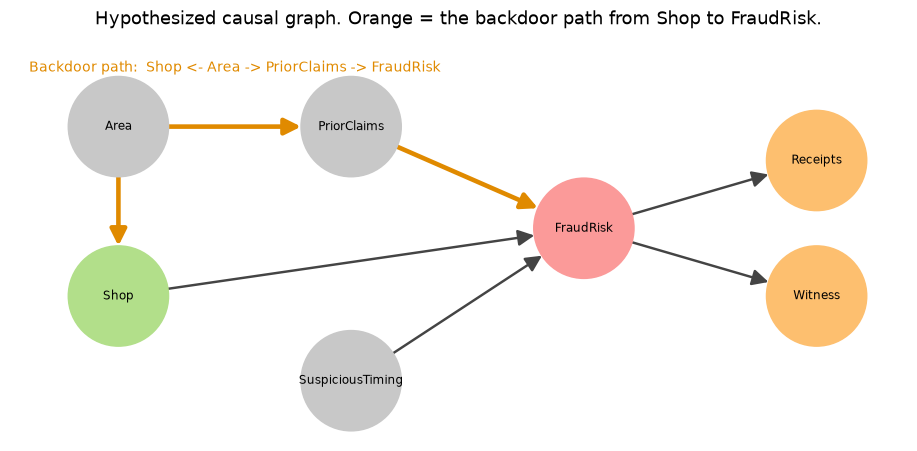

In [44]:
cg = nx.DiGraph([("Area", "Shop"), ("Area", "PriorClaims"), ("PriorClaims", "FraudRisk"), ("SuspiciousTiming", "FraudRisk"),
                 ("Shop", "FraudRisk"), ("FraudRisk", "Receipts"), ("FraudRisk", "Witness")])
cpos = {"Area": (0, 1.6), "Shop": (0, -0.4), "PriorClaims": (2.6, 1.6), "SuspiciousTiming": (2.6, -1.4),
        "FraudRisk": (5.2, 0.4), "Receipts": (7.8, 1.2), "Witness": (7.8, -0.4)}
ccolors = {"Area": "#c8c8c8", "Shop": "#b2df8a", "PriorClaims": "#c8c8c8", "SuspiciousTiming": "#c8c8c8",
           "FraudRisk": "#fb9a99", "Receipts": "#fdbf6f", "Witness": "#fdbf6f"}
backdoor = {("Area", "Shop"), ("Area", "PriorClaims"), ("PriorClaims", "FraudRisk")}
fig, ax = plt.subplots(figsize=(10.5, 4.8))
nx.draw_networkx_nodes(cg, cpos, ax=ax, node_size=4300, node_color=[ccolors[n] for n in cg.nodes])
nx.draw_networkx_labels(cg, cpos, ax=ax, font_size=8)
nx.draw_networkx_edges(cg, cpos, ax=ax, edgelist=[e for e in cg.edges if e not in backdoor], node_size=4300,
                       arrowsize=22, edge_color="#444", width=1.6)
nx.draw_networkx_edges(cg, cpos, ax=ax, edgelist=[e for e in cg.edges if e in backdoor], node_size=4300,
                       arrowsize=22, edge_color="#e08a00", width=3)
ax.text(1.3, 2.25, "Backdoor path:  Shop <- Area -> PriorClaims -> FraudRisk", color="#e08a00", fontsize=9, ha="center")
ax.set_xlim(-1.2, 8.8); ax.set_ylim(-2.1, 2.7); ax.axis("off")
ax.set_title("Hypothesized causal graph. Orange = the backdoor path from Shop to FraudRisk.")
plt.show()

### Step 1: Look at the data
Compare the fraud share of claims at the shop with claims at the three shops that raised no flags (Crescent Repair, Delta Motors, Eastside Auto).

In [45]:
REFERENCE = ["Crescent Repair", "Delta Motors", "Eastside Auto"]
def naive_effect(shop):
    sub = claims[claims["Shop"].isin([shop] + REFERENCE)]
    return sub[sub["Shop"] == shop]["FraudRisk"].mean() - sub[sub["Shop"].isin(REFERENCE)]["FraudRisk"].mean()

print("SEEING (the data alone): extra fraud share at the shop compared with the three reference shops")
print(f"  Bayview Collision: {100 * naive_effect('Bayview Collision'):+.1f} percentage points")
print(f"  Apex Auto Body:    {100 * naive_effect('Apex Auto Body'):+.1f} percentage points")

SEEING (the data alone): extra fraud share at the shop compared with the three reference shops
  Bayview Collision: +12.6 percentage points
  Apex Auto Body:    +71.8 percentage points


Both look bad, and Bayview Collision looks like a shop with a problem. That is the rung 1 reading.

### Step 2: Hold the common cause fixed
To block the backdoor path, compare shops **within the same area** and then combine the areas, weighting by how common each area is. This is the same adjustment as before, with Area as the thing held fixed.

<details open>
<summary><b>Dig deeper: the adjustment in symbols</b></summary>

For a shop S and the three reference shops R, the adjusted effect is

**effect = sum over areas a of  share(a) × ( fraud rate of S in a − fraud rate of R in a )**

where share(a) is the fraction of all claims that come from area *a*. Each term compares like with like (same area), so the area cannot explain the difference. Then the areas are averaged using their overall weights. It only works if Area really is the common cause and nothing else unmeasured is. That is an assumption we argue for, not something the data proves.
</details>

> **Narrate:** Now hold the area fixed. Compare Bayview with the reference shops inside Riverside, then inside Northgate, and combine the two comparisons, weighting each area by how common it is. Within Riverside, Bayview and the other shops look nearly alike, and within Northgate they do too. The adjusted effect for Bayview is a drop of 0.3 percentage points, which is nothing. For Apex it is a rise of 69.5 points. Bayview is innocent. Apex is not.

In [46]:
area_share = claims["Area"].value_counts(normalize=True)

def adjusted_effect(shop):
    sub = claims[claims["Shop"].isin([shop] + REFERENCE)]
    total = 0
    for a in AREAS:
        g = sub[sub["Area"] == a]
        total += area_share[a] * (g[g["Shop"] == shop]["FraudRisk"].mean() - g[g["Shop"].isin(REFERENCE)]["FraudRisk"].mean())
    return total

within = (claims[claims["Shop"].isin(["Bayview Collision"] + REFERENCE)]
          .assign(Group=lambda d: np.where(d["Shop"] == "Bayview Collision", "Bayview Collision", "reference shops"))
          .groupby(["Area", "Group"])["FraudRisk"].agg(claims="size", fraud_share="mean").reset_index())
print("Within each area, Bayview Collision against the reference shops:")
print(within.to_string(index=False))
print()
print("ADJUSTING FOR AREA: extra fraud share at the shop")
print(f"  Bayview Collision: {100 * adjusted_effect('Bayview Collision'):+.1f} percentage points")
print(f"  Apex Auto Body:    {100 * adjusted_effect('Apex Auto Body'):+.1f} percentage points")

Within each area, Bayview Collision against the reference shops:
     Area             Group  claims  fraud_share
Northgate Bayview Collision     241        0.108
Northgate   reference shops    3992        0.118
Riverside Bayview Collision     885        0.306
Riverside   reference shops     515        0.287

ADJUSTING FOR AREA: extra fraud share at the shop
  Bayview Collision: -0.3 percentage points
  Apex Auto Body:    +69.5 percentage points


**Look at the first table.** Within Riverside, Bayview Collision is about the same as the reference shops, and within Northgate it is about the same too. The shop looked risky because **most of its customers live in Riverside**, where prior claims and fraud are more common. Once the area is held fixed, the Bayview effect is about zero. **Apex Auto Body** stays high in both areas: its effect barely moves.

### Step 3: Do it in the machine
We can also test the hypothesis directly. In a simulation, we can **force** every claim to use a given shop (`do(Shop = ...)`) and see what happens to the fraud rate, with everything else about each claim unchanged.

> **Narrate:** Now the check we can only do because we built the world. We reach into the machine and force every claim to go to Bayview, then to Crescent, then to Apex, keeping everything else about each claim as it was. This is what the do() notation means: intervene instead of observing. The fraud rate is the same for Bayview and Crescent, 0.158, and jumps to 0.85 for Apex. The adjustment from data got the right answer, and now we can see it did.

In [47]:
M = 200000
U2 = draw_noise2(M, np.random.default_rng(31))
def fraud_rate_if_every_claim_uses(shop):
    return world2(U2, do={"Shop": np.full(M, shop)})["FraudRisk"].mean()

print(f"Fraud rate as things are:                {world2(U2)['FraudRisk'].mean():.4f}")
print(f"do(every claim uses Crescent Repair):    {fraud_rate_if_every_claim_uses('Crescent Repair'):.4f}")
print(f"do(every claim uses Bayview Collision):  {fraud_rate_if_every_claim_uses('Bayview Collision'):.4f}")
print(f"do(every claim uses Apex Auto Body):     {fraud_rate_if_every_claim_uses('Apex Auto Body'):.4f}")

Fraud rate as things are:                0.1994
do(every claim uses Crescent Repair):    0.1581
do(every claim uses Bayview Collision):  0.1581
do(every claim uses Apex Auto Body):     0.8515


Sending every claim to Bayview Collision gives **exactly the same fraud rate** as sending every claim to Crescent Repair. The shop has no effect. Sending every claim to Apex Auto Body raises it sharply.

### The results side by side

In [48]:
results = pd.DataFrame({
    "Seeing (data alone)":      [100 * naive_effect("Bayview Collision"), 100 * naive_effect("Apex Auto Body")],
    "Adjusting for Area":       [100 * adjusted_effect("Bayview Collision"), 100 * adjusted_effect("Apex Auto Body")],
    "do() in the machine":      [100 * (fraud_rate_if_every_claim_uses("Bayview Collision") - fraud_rate_if_every_claim_uses("Crescent Repair")),
                                 100 * (fraud_rate_if_every_claim_uses("Apex Auto Body") - fraud_rate_if_every_claim_uses("Crescent Repair"))],
}, index=["Bayview Collision", "Apex Auto Body"])
results.columns = [c + " (points)" for c in results.columns]
results

,Seeing (data alone) (points),Adjusting for Area (points),do() in the machine (points)
Bayview Collision,12.620,-0.308,0.000
Apex Auto Body,71.802,69.538,69.335


**The machine, opened.** This is the truth we planted when we built the claims, which is the only reason we can check the answer:
- **Apex Auto Body** runs a fraud ring. Claims there are fraudulent about 85% of the time, whatever the claimant's history. That is a real effect of the shop.
- **Bayview Collision** has **no effect on fraud**. It serves Riverside, where prior claims are common (40% of claimants, against 8% in Northgate), and prior claims raise fraud.
- The six adjusters have no effect either.

Adjusting for the common cause recovered the truth for both shops: no effect for Bayview, a large one for Apex. The data alone got Bayview wrong. In real life we never get to open the machine, which is why the **graph has to be argued for**, and a confounder we did not think of would fool the adjustment too.

### Turning it into action
The graph found two shops. The causal check says what to do about each:

> **Narrate:** So where should the insurer look harder? We compare five strategies by how many claims each reviews and how many of those turn out to be fraud. Reviewing everything wastes effort. Reviewing Bayview is barely better than average. Reviewing the claims the model flagged is very efficient. And the unflagged Apex claims are the surprise: the model catches 69% of the fraud at Apex, so 98 fraudulent Apex claims got through, and two thirds of the unflagged Apex claims we would review are fraud.

In [49]:
isf = claims["FraudRisk"].values == 1
fl = claims["Flagged"].values
apex = (claims["Shop"] == "Apex Auto Body").values
bay = (claims["Shop"] == "Bayview Collision").values
missed_at_apex = int((isf & apex & ~fl).sum())

triage = pd.DataFrame([
    ("Review every claim",                          len(claims),   int(isf.sum())),
    ("Review every claim at Bayview Collision",     int(bay.sum()), int((isf & bay).sum())),
    ("Review every claim at Apex Auto Body",        int(apex.sum()), int((isf & apex).sum())),
    ("Review the claims the model flagged",         int(fl.sum()),  int((isf & fl).sum())),
    ("Review Apex claims the model did NOT flag",   int((apex & ~fl).sum()), missed_at_apex),
], columns=["Strategy", "Claims reviewed", "Fraud found"])
triage["Hit rate"] = (100 * triage["Fraud found"] / triage["Claims reviewed"]).map("{:.0f}%".format)
print(triage.to_string(index=False))
print(f"\nThe model catches {100 * fl[isf & apex].mean():.0f}% of the fraud at Apex Auto Body, so {missed_at_apex} fraudulent Apex claims got through.")

                                 Strategy  Claims reviewed  Fraud found Hit rate
                       Review every claim             6000         1231      21%
  Review every claim at Bayview Collision             1126          297      26%
     Review every claim at Apex Auto Body              367          314      86%
      Review the claims the model flagged             1111         1034      93%
Review Apex claims the model did NOT flag              149           98      66%

The model catches 69% of the fraud at Apex Auto Body, so 98 fraudulent Apex claims got through.


| Finding | Rung | Action |
|---|---|---|
| Apex Auto Body raises fraud, and the model misses a good share of it | 2 | **Audit the shop.** Reviewing its unflagged claims finds fraud the model let through. |
| Bayview Collision looks risky but has no effect once the area is accounted for | 2 | **Do not penalize the shop or its customers.** Reviewing all of its claims gives a hit rate only slightly above average, and closing the shop would not reduce fraud. |
| Adjusters differ by amounts small enough to be chance | 1 | **No action.** |

The hit rate for "review every claim at Bayview" is higher than average, so it would look like a good rule. It would send honest Riverside customers, like Maria, to a slow track for a reason that is not a cause.

In [50]:
note("7", "Is my repair shop to blame?", "Causal graph, adjustment, do()", "2",
     f"No. Bayview's effect on fraud is {100 * adjusted_effect('Bayview Collision'):+.1f} points once area is held fixed (raw gap {100 * naive_effect('Bayview Collision'):+.1f}). "
     f"Apex's is {100 * adjusted_effect('Apex Auto Body'):+.1f}.")

<details open>
<summary><b>Go further on your own: Part 7</b></summary>

- **Read:** Pearl and Mackenzie, *The Book of Why*, the chapters on the ladder of causation and on confounding.
- **Try:** change `RING_P` (how often an Apex claim is fraud) and rerun. Does the adjusted effect follow it?
- **Try:** adjust for the wrong thing. Hold `FraudRisk` fixed instead of `Area` and see what the "effect" of the shop becomes. This is how a bad adjustment fools you.
- **Think:** the adjustment assumes Area is the only common cause. Name one thing the insurer does not record that could break that assumption.
</details>

## Part 8: Does a false alarm cost us customers? (rung 2)

> **Narrate:** Maria did not renew. Was that the false alarm's fault, or would she have left anyway? The trap is the same as with the shop. Customers who get flagged are mostly customers with a prior claim, and customers with a prior claim leave more often whether or not they are flagged. So the raw gap blames the flag for two effects at once. Hold prior claims fixed, and the flag's own cost is smaller, but it is real. Then we ask a question an insurer cares about: of the honest customers lost after a false alarm, how many were lost because of it?

> **Concept:** The same tools, a new question. Look (rung 1), find the common cause, adjust, then check against the machine (rung 2). Here the group we ask about is the **honest customers the model flagged**, which is why the adjustment weights the groups by the mix among *flagged* customers.

So far the question was about fraud. A business also asks about **customers**: when the model flags an honest claimant, do they renew their policy less often? And is that the *flag's* doing, or would those customers have left anyway?

We state the hypothesis and the graph first.
- **H3:** Being flagged **lowers the chance that an honest customer renews** (the slow review, the document requests, the feeling of being accused).
- **PriorClaims** has two jobs. It makes the model flag a claim (the model reads it), and it also affects renewal **for reasons of its own**: customers with a claim history tend to leave more often, flagged or not.
- **Tenure** also affects renewal, but it has nothing to do with the flag.

So there is a **backdoor path** from the flag to renewal: *Flagged ← PriorClaims → Renewal*. Honest customers who are flagged are mostly customers with a prior claim, who would renew less anyway. Reading the gap straight from the data mixes the flag's effect with the prior-claims effect. This is the same trap as the shop, with PriorClaims as the common cause.

**Who are we asking about?** Honest customers who were flagged: the people a false alarm actually touched, including Maria.

### More customers, for a steadier answer
Only 77 honest customers were flagged in this quarter's 6,000 claims, too few for a steady estimate. The insurer has the same kind of records for earlier quarters, so we use a **CRM extract of 24,000 closed claims**: this quarter's 6,000 plus 18,000 earlier ones.

> **Narrate:** Maria did not renew. Was the flag to blame? Part 7 gave us the method, so we use it again, on a new question. One problem: this quarter has only 77 honest customers who were flagged, which is too few to be sure of anything. So we add earlier quarters, produced by the same machines with new random numbers, to reach 24,000 claims and 260 honest customers who were flagged.
>
> **Tool:** `numpy` and `pandas`. The same simulation machine, run again.

In [51]:
# ----- Earlier quarters, produced by the same machines (new random numbers) -----
N_OLD = 18000
older = world2(draw_noise2(N_OLD, np.random.default_rng(15)))
older["Flagged"] = model_flag(older)
(older["Tenure"], older["Premium"], older["WaitDays"], _, older["Renewed"]) = crm_outcomes(
    older["PriorClaims"].values, older["Flagged"].values, draw_crm_noise(N_OLD, np.random.default_rng(22)))

this_q = claims[["Area", "Shop", "PriorClaims", "FraudRisk"]].copy()
this_q["Flagged"], this_q["Tenure"], this_q["Premium"], this_q["WaitDays"], this_q["Renewed"] = flag_q, tenure, premium, wait, renewed

keep = ["Area", "Shop", "PriorClaims", "FraudRisk", "Flagged", "Tenure", "Premium", "WaitDays", "Renewed"]
crm_all = pd.concat([this_q[keep], older[keep]], ignore_index=True)
honest = crm_all[crm_all["FraudRisk"] == 0]

print(f"CRM extract: {len(crm_all):,} claims, of which {len(honest):,} legitimate.")
print(f"Legitimate customers who were flagged (false alarms): {int((honest['Flagged'] == 1).sum())}")
print(f"Overall renewal rate: {100 * crm_all['Renewed'].mean():.1f}%")

CRM extract: 24,000 claims, of which 19,083 legitimate.
Legitimate customers who were flagged (false alarms): 260
Overall renewal rate: 77.2%


### Step 1: Look at the data (rung 1)
Compare renewal for honest customers who were flagged with honest customers who were not.

In [52]:
flagged_h, unflagged_h = honest[honest["Flagged"] == 1], honest[honest["Flagged"] == 0]
naive_loss = 100 * (unflagged_h["Renewed"].mean() - flagged_h["Renewed"].mean())

print(f"Honest customers NOT flagged: {100 * unflagged_h['Renewed'].mean():.1f}% renewed  ({len(unflagged_h):,} customers)")
print(f"Honest customers flagged:     {100 * flagged_h['Renewed'].mean():.1f}% renewed  ({len(flagged_h):,} customers)")
print(f"\nSEEING: flagged customers renew {naive_loss:.1f} percentage points less often.")
print(f"Share with a prior claim:  flagged {100 * flagged_h['PriorClaims'].mean():.0f}%   not flagged {100 * unflagged_h['PriorClaims'].mean():.0f}%")

Honest customers NOT flagged: 81.8% renewed  (18,823 customers)
Honest customers flagged:     58.1% renewed  (260 customers)

SEEING: flagged customers renew 23.8 percentage points less often.
Share with a prior claim:  flagged 53%   not flagged 8%


Flagged honest customers renew much less often. But look at the last line: **more than half of the flagged honest customers have a prior claim, against a small fraction of the unflagged**. The two groups are not alike to begin with, which is the backdoor path at work.

### Step 2: Hold the common cause fixed
Compare within each prior-claims group, then combine the groups using the mix among the **flagged** customers (because they are the people we are asking about).

In [53]:
within_prior = (honest.groupby(["PriorClaims", "Flagged"]).agg(customers=("Renewed", "size"), renewed_pct=("Renewed", lambda s: 100 * s.mean()))
                .reset_index())
print(within_prior.to_string(index=False))

def retention_effect(df):
    f, p, r = df["Flagged"].values, df["PriorClaims"].values, df["Renewed"].values
    n_flagged = (f == 1).sum()
    total = 0.0
    for k in (0, 1):
        weight = ((f == 1) & (p == k)).sum() / n_flagged
        total += weight * (r[(f == 0) & (p == k)].mean() - r[(f == 1) & (p == k)].mean())
    return 100 * total

adj_loss = retention_effect(honest)
rng_b = np.random.default_rng(0)
boot = [retention_effect(honest.iloc[rng_b.integers(len(honest), size=len(honest))]) for _ in range(300)]
print(f"\nADJUSTING FOR PRIOR CLAIMS: flagged customers renew {adj_loss:.1f} points less often (give or take {np.std(boot):.1f})")

 PriorClaims  Flagged  customers  renewed_pct
           0        0      17410       82.860
           0        1        123       68.293
           1        0       1413       69.214
           1        1        137       48.905

ADJUSTING FOR PRIOR CLAIMS: flagged customers renew 17.6 points less often (give or take 3.1)


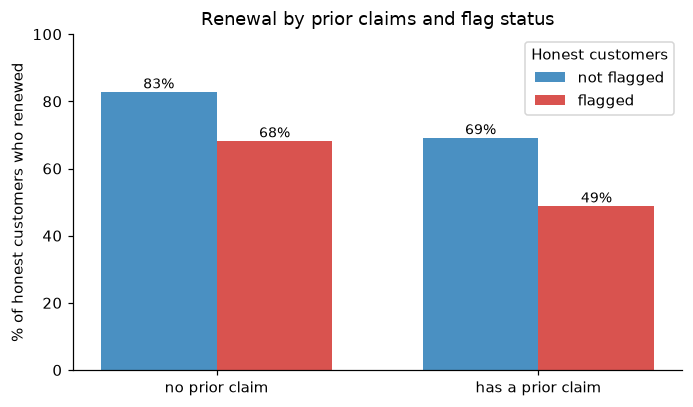

In [54]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
x = np.arange(2); wd = 0.36
for j, (flag_val, color, lab) in enumerate([(0, "#4a90c2", "not flagged"), (1, "#d9534f", "flagged")]):
    vals = [within_prior[(within_prior["PriorClaims"] == k) & (within_prior["Flagged"] == flag_val)]["renewed_pct"].iloc[0] for k in (0, 1)]
    bars = ax.bar(x + (j - 0.5) * wd, vals, wd, color=color, label=lab)
    for b_, v_ in zip(bars, vals): ax.text(b_.get_x() + b_.get_width() / 2, v_ + 1, f"{v_:.0f}%", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(["no prior claim", "has a prior claim"])
ax.set_ylabel("% of honest customers who renewed"); ax.set_ylim(0, 100); ax.legend(title="Honest customers")
ax.set_title("Renewal by prior claims and flag status")
plt.tight_layout(); plt.show()

**Reading the picture.** In **both** groups, flagged customers renew less. So the flag does cost renewals. But customers with a prior claim renew less than customers without one even when **not** flagged, and most flagged honest customers have a prior claim. The data alone blamed the flag for **both** effects. Holding prior claims fixed separates them, and the flag's own share is smaller.

### Step 3: Do it in the machine
In the simulation we can ask the question directly. Take every honest customer the model flagged, and compute the chance they renew **with** the flag and **without** it, keeping everything else about them unchanged.

> **Narrate:** The same check as before: reach into the machine and take the flag away from the honest customers it flagged. Their chance of renewing rises by 18.9 points. The raw gap in the data was 23.8 points, which overstates it, because flagged customers are mostly customers with prior claims, who leave more often anyway. Holding prior claims fixed gave 17.6, give or take 3.1. That is close to the truth. The flag costs a real, measurable share of renewals.

In [55]:
M_BIG = 300000
U_big = draw_noise2(M_BIG, np.random.default_rng(41))
V_big = draw_crm_noise(M_BIG, np.random.default_rng(42))
big = world2(U_big)
hit = (big["FraudRisk"].values == 0) & (model_flag(big) == 1)             # honest customers the model flags

ten_big = np.clip(V_big["tenure"], 0.5, 25)
p_with    = p_renew(big["PriorClaims"].values, 1, ten_big)
p_without = p_renew(big["PriorClaims"].values, 0, ten_big)
true_loss = 100 * (p_without[hit] - p_with[hit]).mean()
print(f"DOING: for honest customers the model flags, removing the flag raises their chance of renewing by {true_loss:.1f} points  ({int(hit.sum()):,} simulated customers)")

pd.DataFrame({"Seeing (data alone)": [naive_loss], "Adjusting for prior claims": [adj_loss], "do() in the machine": [true_loss]},
             index=["Renewal lost to a false alarm (points)"])

DOING: for honest customers the model flags, removing the flag raises their chance of renewing by 18.9 points  (3,425 simulated customers)


,Seeing (data alone),Adjusting for prior claims,do() in the machine
Renewal lost to a false alarm (points),23.759,17.593,18.916


**The machine, opened.** This is the truth we planted:
- Being flagged lowers the **odds** of renewing, and prior claims do too, by a similar amount, **independently** of each other.
- Tenure helps a little (long-standing customers stay).
- A fraud review adds about two weeks to the time it takes to settle.

The data alone overstated the harm of the flag, because it also carried the effect of prior claims. Adjusting for the common cause came close to the truth (the small difference is chance in a finite sample). We give a **range**, not a single number, since we only have finitely many customers.

| Finding | Rung | What it means for the business |
|---|---|---|
| Flagged customers renew less, and wait longer | 1 | Look after them; they are a segment worth watching |
| Part of the gap is the flag, part is prior claims | 2 | A false alarm has a **real, measurable cost**, smaller than the raw gap suggests |
| Maria's own renewal | 3 | Part 10 |

### Counting the cost: how many lapses did the false alarm cause?
A percentage is hard to feel. So count. Take every honest customer the model flagged in the large simulation, and ask how many of them **lapsed**, and how many of those lapses would not have happened without the flag. For each customer, the chance of lapsing was one minus her chance of renewing. The extra lapses caused by the flag are the difference between her chance of renewing without the flag and with it. These are expected counts, summed over customers.

In [56]:
lapsed_expected      = (1 - p_with[hit]).sum()                 # expected lapses among honest flagged customers
preventable_expected = (p_without[hit] - p_with[hit]).sum()    # of those, lapses that the flag itself caused
share_preventable    = preventable_expected / lapsed_expected

print(f"Honest customers the model flagged (simulated): {int(hit.sum()):,}")
print(f"Expected to lapse:                                {lapsed_expected:,.0f}  ({100 * lapsed_expected / hit.sum():.0f}% of them)")
print(f"Lapses that would not have happened without the flag: {preventable_expected:,.0f}")
print(f"\nSo about {100 * share_preventable:.0f}% of the honest customers lost after a false alarm were lost because of the false alarm.")
print(f"Put another way, roughly {round(10 * share_preventable)} in 10 of those lapses is the insurer's own doing.")

Honest customers the model flagged (simulated): 3,425
Expected to lapse:                                1,494  (44% of them)
Lapses that would not have happened without the flag: 648

So about 43% of the honest customers lost after a false alarm were lost because of the false alarm.
Put another way, roughly 4 in 10 of those lapses is the insurer's own doing.


### How sure are we? Change the strength of the flag's effect
The flag's effect in the machine is a setting (`B_FLAG`, which pushes the chance of renewing down; the table shows its strength as a positive number). The data-driven method (hold prior claims fixed) should recover whatever the true effect is, not just one value. We try four settings. For each, we regenerate renewals for the same 24,000 customers with fresh random numbers, estimate the loss from the data, and compare with the truth in the machine. Then the original setting is restored.

In [57]:
saved_b_flag = B_FLAG
sens_rows = []
try:
    for b in (-0.3, -0.6, -0.9, -1.2):
        B_FLAG = b
        V_s = draw_crm_noise(len(crm_all), np.random.default_rng(77))
        r_s = crm_outcomes(crm_all["PriorClaims"].values, crm_all["Flagged"].values, V_s)[4]
        h_s = crm_all.assign(Renewed=r_s)
        h_s = h_s[h_s["FraudRisk"] == 0]
        truth_s = 100 * (p_renew(big["PriorClaims"].values, 0, ten_big)[hit] - p_renew(big["PriorClaims"].values, 1, ten_big)[hit]).mean()
        sens_rows.append((abs(b), 100 * (h_s[h_s["Flagged"] == 0]["Renewed"].mean() - h_s[h_s["Flagged"] == 1]["Renewed"].mean()),
                          retention_effect(h_s), truth_s))
finally:
    B_FLAG = saved_b_flag                                           # always restore the original setting

sens = pd.DataFrame(sens_rows, columns=["Flag strength", "Seeing (raw gap)", "Adjusted for prior claims", "Truth in the machine"])
print(sens.round(1).to_string(index=False))
print(f"\nSetting restored to {B_FLAG}.")

 Flag strength  Seeing (raw gap)  Adjusted for prior claims  Truth in the machine
         0.300            11.200                      4.000                 5.700
         0.600            17.400                     10.200                12.100
         0.900            23.900                     16.700                18.900
         1.200            29.700                     22.500                26.000

Setting restored to -0.9.


**Reading the table.** The raw gap is always larger than the truth, because it carries the prior-claims effect too. The adjusted estimate rises and falls with the truth, and it sits a little below it in every row. All four rows reuse the same customers and the same random numbers, so they share one sample's chance error, which is about the size of the give-or-take figure earlier (about 3 points). That is why the gap looks alike in every row. (The 0.9 row is not the same as the earlier result, because the random numbers here are new.) The method is not tuned to one answer: it follows the effect up and down.

In [58]:
note("8", "Did the false alarm cost the insurer my business?", "Adjustment, do()", "2",
     f"The flag cost about {adj_loss:.1f} points of renewal (raw gap {naive_loss:.1f}). About {100 * share_preventable:.0f}% of honest flagged customers who lapse were lost to the flag.")

<details open>
<summary><b>Go further on your own: Part 8</b></summary>

- **Read:** the section on confidence intervals in any introductory statistics text, and compare it with the "give or take" figure printed above.
- **Try:** raise the number of earlier quarters from 18,000 to 40,000 (`N_OLD`). Does the give-or-take figure shrink? By roughly how much?
- **Think:** the machine's renewal chance depends on tenure. Our adjustment holds only prior claims fixed. Why does the estimate still come out close?
</details>

## Part 9: What is a policy worth? A business case

> **Narrate:** Two facts are on the table. The model misses a good share of the fraud at Apex. And a false alarm costs real customers. So what should the insurer do with that? We compare three review policies on the same quarter, and put dollars next to each. Be clear about what is solid and what is assumed. The counts (how many claims, how much fraud) come from the data. The dollar values are stated assumptions, and we show what happens when they change.

> **Concept:** A **business case** is a cost-benefit table, and it is only as honest as its assumptions. The measured parts (Part 7's fraud counts, Part 8's renewal loss) carry evidence. The assumed parts (what a caught fraud is worth, what a review costs, how often a review catches fraud) carry none, so each is a labeled setting you can change.

Part 7 said the model misses a good share of the fraud at Apex Auto Body. Part 8 put a price on a false alarm. Now put them together and compare **three review policies**. In each, the insurer also sends the claims that the model did **not** flag from a given group to the slow fraud review:

1. Also review every unflagged **Bayview Collision** claim.
2. Also review every unflagged **Riverside** claim.
3. Also review every unflagged **Apex Auto Body** claim.

**These dollar figures and the detection rate are illustrative assumptions, not facts about any real insurer.** Change them and rerun to see how the answer moves.

<details open>
<summary><b>Dig deeper: what each column means and what is assumed</b></summary>

| Item | Source | Assumption stated |
|---|---|---|
| Claims reviewed, fraud found | Data (this quarter) | A fraudulent claim counts as "found" only if the review catches it, at the **detection rate** below |
| Renewal lost per honest customer reviewed | Part 8, **separately for customers with and without a prior claim** | A fraud review hurts renewal as much as a flag does, because both bring the same slow review |
| Dollar value of a caught fraud | Assumption | $8,000 |
| Cost of reviewing one claim | Assumption | $150 |
| Value of a renewal | Premium times assumed years | 3 years of premium |
| **Detection rate** | Assumption | Starts at 100%: a review catches every fraud it looks at. Real reviews miss some, so we test lower rates. |
</details>

> **Narrate:** Time to put dollars on it, and to be careful about which numbers are solid and which are assumed. The counts of claims and fraud are data. The value of a caught fraud, the cost of a review, and the share of fraud a review actually catches are assumptions, written in capital letters at the top of the cell so that you can change them and rerun. The result: reviewing the unflagged Apex claims pays for itself by a wide margin even when we assume reviewers catch far less than everything. Reviewing every Bayview or Riverside claim costs more than it saves, at every detection rate we tried.
>
> **Tool:** `pandas`. The business case is a small table with arithmetic, nothing more. That is deliberate. A business case should be simple enough that a manager can check it.

In [59]:
FRAUD_SAVING   = 8000      # ASSUMPTION: dollars saved each time a fraudulent claim is caught
REVIEW_COST    = 150       # ASSUMPTION: dollars to review one extra claim
LIFETIME_YEARS = 3         # ASSUMPTION: years of premium we expect from a customer who renews
DETECTION      = 1.0       # ASSUMPTION: share of fraudulent claims that a review actually catches (tested below)

def usd(x): return f"-${abs(x):,.0f}" if x < 0 else f"${x:,.0f}"

# Renewal lost to a review, from Part 8, separately for customers without and with a prior claim
wp = within_prior.set_index(["PriorClaims", "Flagged"])["renewed_pct"]
eff_prior = {k: (wp[(k, 0)] - wp[(k, 1)]) / 100 for k in (0, 1)}
print("Renewal lost to a fraud review (share of customers), from Part 8:")
print(f"   no prior claim: {100 * eff_prior[0]:.1f} points     prior claim: {100 * eff_prior[1]:.1f} points\n")

prem = pd.Series(premium, index=claims.index)
unflagged = ~claims["Flagged"].values
is_fraud_q = claims["FraudRisk"].values == 1
loss_rate = claims["PriorClaims"].map(eff_prior)                      # each honest customer's renewal loss

def policy_row(name, group_mask, detection=DETECTION):
    m = group_mask & unflagged
    n, fraud_in_group = int(m.sum()), int((m & is_fraud_q).sum())
    fraud_found = detection * fraud_in_group
    honest_hit = m & ~is_fraud_q
    value_lost = (prem[honest_hit] * loss_rate[honest_hit]).sum() * LIFETIME_YEARS    # renewals lost x premium x years
    cost = n * REVIEW_COST
    saved = fraud_found * FRAUD_SAVING
    return dict(Policy=name, ClaimsReviewed=n, FraudInGroup=fraud_in_group, HonestCustomersReviewed=int(honest_hit.sum()),
                FraudSaved=saved, ReviewCost=cost, PremiumValueLost=value_lost, Net=saved - cost - value_lost,
                BreakEvenDetection=(cost + value_lost) / max(fraud_in_group * FRAUD_SAVING, 1))

POLICIES = [("Also review unflagged Bayview claims", (claims["Shop"] == "Bayview Collision").values),
            ("Also review unflagged Riverside claims", (claims["Area"] == "Riverside").values),
            ("Also review unflagged Apex claims", (claims["Shop"] == "Apex Auto Body").values)]
policy_table = pd.DataFrame([policy_row(n_, m_) for n_, m_ in POLICIES])
shown = policy_table.copy()
for c_ in ["FraudSaved", "ReviewCost", "PremiumValueLost", "Net"]: shown[c_] = shown[c_].map(usd)
shown["BreakEvenDetection"] = (100 * shown["BreakEvenDetection"]).map("{:.0f}%".format)
print(shown.to_string(index=False))

Renewal lost to a fraud review (share of customers), from Part 8:
   no prior claim: 14.6 points     prior claim: 20.3 points

                                Policy  ClaimsReviewed  FraudInGroup  HonestCustomersReviewed FraudSaved ReviewCost PremiumValueLost       Net BreakEvenDetection
  Also review unflagged Bayview claims             835            29                      806   $232,000   $125,250         $485,614 -$378,864               263%
Also review unflagged Riverside claims            1023            61                      962   $488,000   $153,450         $593,008 -$258,458               153%
     Also review unflagged Apex claims             149            98                       51   $784,000    $22,350          $31,592  $730,058                 7%


**How to read the table.** *FraudSaved* is the benefit. *ReviewCost* and *PremiumValueLost* are the costs. *Net* is the benefit minus the costs. *BreakEvenDetection* is the share of the fraud in the group that a review would have to catch for the policy to pay for itself, using the assumed $8,000. A value above 100% means the policy cannot pay for itself even if the review catches everything.

In [60]:
sens_policy = pd.DataFrame({"Detection rate": [f"{int(100 * d)}%" for d in (1.0, 0.8, 0.6, 0.4)]})
for name_, mask_ in POLICIES:
    sens_policy[name_.replace("Also review unflagged ", "").replace(" claims", "")] = [usd(policy_row(name_, mask_, d)["Net"]) for d in (1.0, 0.8, 0.6, 0.4)]
print("Net value of each policy as the review's detection rate falls:\n")
print(sens_policy.to_string(index=False))

Net value of each policy as the review's detection rate falls:

Detection rate   Bayview Riverside     Apex
          100% -$378,864 -$258,458 $730,058
           80% -$425,264 -$356,058 $573,258
           60% -$471,664 -$453,658 $416,458
           40% -$518,064 -$551,258 $259,658


**What holds up, and what does not.** The ranking depends on the assumptions, so read the two tables together. Where the policy stays above zero as the detection rate falls, the conclusion is sturdy. Where it flips sign, the dollar figures are doing the work, not the data. One thing does not depend on any dollar figure: **Part 7 found that Bayview has no effect on fraud**, so reviewing Bayview claims cannot reduce fraud by acting on the shop. This table adds what that choice costs the customer relationship.

In [61]:
note("9", "What would reviewing more claims be worth?", "Cost table with stated assumptions", "2",
     f"Under the assumptions, unflagged Apex claims net {usd(policy_table.iloc[2]['Net'])}; Bayview {usd(policy_table.iloc[0]['Net'])}; Riverside {usd(policy_table.iloc[1]['Net'])}. Dollar values are assumed.")

<details open>
<summary><b>Go further on your own: Part 9</b></summary>

- **Try:** change `FRAUD_SAVING`, `REVIEW_COST` and `DETECTION` at the top of the cell, one at a time, and watch the Apex policy. At what value does it stop paying for itself?
- **Think:** a manager asks, "How sure are you about the dollar figures?" What do you say? Which of the numbers in this table came from data, and which did not?
</details>

## Part 10: Maria's own story (rung 3)

> **Narrate:** Everything so far was about groups. Now we come back to Maria herself, and ask two questions that only the third rung can answer. First: would she have stayed if the insurer had not flagged her? The honest answer is "possibly, about four chances in ten", and it is worth seeing why it cannot be sharper than that. Second: what would it have taken to clear her claim? That answer is exact, and it is something she can act on.

> **Concept:** **Rung 3 is about one case.** The recipe has three steps: **recall** what was special about this person (her own noise), **change** one thing, and **replay** with her noise kept. For a measured number the replay gives one answer. For a yes-or-no outcome, recall only narrows her hidden number to a range, so the replay gives a probability.

**Her shop first.** Bayview Collision does not appear in any of the equations that produced Maria's fraud status, her receipts or her witness statements. Replaying her case at a different shop would change nothing in her story: her score stays exactly as it is. The shop was part of how she got flagged in a graph picture, and no part of why her clues looked suspicious.

### Question 1: Would Maria have renewed if she had not been flagged?
Maria was a customer for **6.0 years**, paid a **$1,350** premium, and her policy **lapsed**. The insurer's question is a counterfactual about one person: *if she had not been flagged, would she have stayed?*

The steps are the same three, with one difference. Renewal is a **yes or no** outcome, like the fraud status earlier, so her own hidden number (call it her **renewal roll**, a number between 0 and 1) is never recorded.

1. **Recall.** The rule is: a customer renews if her roll is **below** her chance of renewing. With the flag, Maria's chance was a little over one half. She did not renew, so her roll was **above** that chance. That is all we can say about it: it lies somewhere between her chance and 1, like a number in a sealed envelope.
2. **Change.** Remove the flag. Her chance of renewing goes up. Nothing else about her changes: same tenure, same prior claim.
3. **Replay.** With the same roll and a higher bar, would she have cleared it? We cannot say for sure. Her roll could be between the old bar and the new bar (she would have stayed), or above both (she would have left anyway).

The chance of the first case is the share of the sealed-envelope range that lies below the new bar.

> **Narrate:** Now we come back to Maria herself. With the flag, her chance of renewing was 0.525, a coin flip. Without it, 0.731. But she did not renew, so what is the chance she would have, in the world where the flag never happened? We cannot know her hidden dice roll, but we know it landed above 0.525, because she left. Of the rolls above 0.525, those below 0.731 would have renewed. That share is 43%. A probability, not a certainty: this is what a counterfactual about a yes-or-no outcome looks like.

In [62]:
p_flagged  = p_renew(prior=1, flagged=1, tenure=maria_crm["Tenure"])        # her chance of renewing, as she was treated
p_unflagged = p_renew(prior=1, flagged=0, tenure=maria_crm["Tenure"])       # her chance if she had not been flagged

# Her roll is somewhere between p_flagged and 1 (she left). What share of that range is below p_unflagged?
chance_she_would_have_stayed = (p_unflagged - p_flagged) / (1 - p_flagged)

print(f"Maria's chance of renewing as she was treated (flagged):  {p_flagged:.3f}")
print(f"Her chance if she had not been flagged:                   {p_unflagged:.3f}")
print(f"Her roll lies between {p_flagged:.3f} and 1.000, and she would have stayed if it lies below {p_unflagged:.3f}.")
print(f"\nChance that Maria would have renewed without the flag: {chance_she_would_have_stayed:.0%}")

# Check by brute force: many customers like Maria, keep only those who left, and see how many would have stayed
rolls = np.random.default_rng(5).uniform(size=2_000_000)
left = rolls >= p_flagged
print(f"Check by simulation (customers like Maria who left): {100 * (rolls[left] < p_unflagged).mean():.1f}% would have stayed")

Maria's chance of renewing as she was treated (flagged):  0.525
Her chance if she had not been flagged:                   0.731
Her roll lies between 0.525 and 1.000, and she would have stayed if it lies below 0.731.

Chance that Maria would have renewed without the flag: 43%
Check by simulation (customers like Maria who left): 43.4% would have stayed


**Reading the result.** There is **no certain answer** for Maria. About **four chances in ten** that she would have stayed: a real possibility, though less likely than not. Compare this with her receipts, which we replay in the next question: there the recalled number is fixed exactly, and the replay gives one exact answer. Here the outcome was yes or no, so recall leaves a range, and the replay gives a **probability**. A counterfactual for one person is only as sharp as the equation allows.

For the insurer, the useful reading is about the **action**: Maria is a long-standing, honest customer with a substantial chance (a little over four in ten) of having been kept without the false alarm. That is enough to make her worth a personal call, not a form letter.

### Question 2: What would it take to clear her claim?
> **Narrate:** Now the part Maria can use. Her claim looked suspicious to the model for reasons that were partly bad luck in her own paperwork. If we keep her own luck fixed and change only what she can act on (more supporting documents, or a follow-up), at what point does the model clear her?

**Her clues.** This is the same machine as before. We **recall** Maria's own noise (her receipts came out 1.85 worse than the equation predicts, her witness statements 2.0 worse), **change** what she can act on, and **replay**. The answer is advice for getting a correct decision **from this model**. It assumes the extra documents are real documents she can supply, not padding.

<details open>
<summary><b>Dig deeper: recall, change, replay in the code</b></summary>

The receipts equation is `Receipts = 4 + 3 x fraud - 0.5 x documents + noise`. For Maria, `fraud = 0` and `documents = 4.5`, so the equation predicts a receipts score of 1.75. Hers was 3.6, so her noise is **1.85**. Replaying with more documents keeps that 1.85 and lowers the predicted part. The witness equation works the same way with the follow-up. Each plan is then scored by the same model that flagged her. Cost is a stand-in: one unit per document, four per follow-up.
</details>

> **Narrate:** And now the part Maria can use. Her receipts came out worse than the equation predicts, by 1.85, and her witness statements by 2.0. That is her own bad luck, and it stays with her in the replay. We change only what she can act on, supporting documents and a follow-up, and ask the model again. With four extra documents she is still flagged, at 0.586. With five she is cleared, at 0.405. A follow-up alone does not clear her. This is advice that applies to her, and no group average would have given it.

In [63]:
u_receipts = maria["Receipts"] - eq_receipts(maria["FraudRisk"], maria["Docs"], 0.0)
u_witness  = maria["Witness"]  - eq_witness(maria["FraudRisk"], maria["FollowUp"], 0.0)
print(f"Maria's receipt noise: {u_receipts:+.2f}    Maria's witness noise: {u_witness:+.2f}")

def counterfactual_maria(extra_docs=0, follow_up=0):
    r = eq_receipts(maria["FraudRisk"], maria["Docs"] + extra_docs, u_receipts)   # her own noise, new documents
    w = eq_witness(maria["FraudRisk"], follow_up, u_witness)                      # her own noise, new follow-up
    x = pd.DataFrame([dict(PriorClaims=1, SuspiciousTiming=0, Receipts=r, Witness=w)])
    return model.predict_proba(x[features])[0, 1]

COST_DOC, COST_FOLLOWUP = 1, 4
plans = pd.DataFrame([dict(ExtraDocs=e, FollowUp=f, Cost=e * COST_DOC + f * COST_FOLLOWUP, Probability=counterfactual_maria(e, f))
                      for e in range(0, 9) for f in (0, 1)])
plans["Decision"] = np.where(plans["Probability"] < 0.5, "cleared", "still flagged")
print()
print(plans[plans["FollowUp"] == 0].head(8).to_string(index=False))
best = plans[plans["Probability"] < 0.5].sort_values(["Cost", "ExtraDocs"]).iloc[0]
print(f"\nCheapest plan that clears her: {int(best.ExtraDocs)} extra documents, follow-up = {int(best.FollowUp)}, cost {int(best.Cost)}")
print(f"Follow-up alone (no extra documents): probability {counterfactual_maria(0, 1):.3f}")

Maria's receipt noise: +1.85    Maria's witness noise: +2.00

 ExtraDocs  FollowUp  Cost  Probability      Decision
         0         0     0        0.964 still flagged
         1         0     1        0.927 still flagged
         2         0     2        0.860 still flagged
         3         0     3        0.746 still flagged
         4         0     4        0.586 still flagged
         5         0     5        0.405       cleared
         6         0     6        0.246       cleared
         7         0     7        0.136       cleared

Cheapest plan that clears her: 5 extra documents, follow-up = 0, cost 5
Follow-up alone (no extra documents): probability 0.816


**A group answer to compare with.** For a **group** (honest claimants the model flagged, with a prior claim, in the large simulation), we can ask what share would be cleared after *k* extra documents. Each extra document lowers a claimant's receipts mismatch by 0.5, as in the equation.

In [64]:
grp = big[hit & (big["PriorClaims"].values == 1)]
rows_g = []
for k in range(0, 9):
    d = grp[features].copy()
    d["Receipts"] = d["Receipts"] - 0.5 * k                                  # k more documents, same for everyone in the group
    rows_g.append((k, 100 * (model.predict_proba(d)[:, 1] < 0.5).mean(), counterfactual_maria(k, 0)))
group_vs_maria = pd.DataFrame(rows_g, columns=["Extra documents", "Group: % cleared", "Maria: model's fraud probability"])
print(f"Group: {len(grp):,} simulated honest, flagged claimants with a prior claim.\n")
print(group_vs_maria.round(3).to_string(index=False))

Group: 1,781 simulated honest, flagged claimants with a prior claim.

 Extra documents  Group: % cleared  Maria: model's fraud probability
               0             0.000                             0.964
               1            38.349                             0.927
               2            61.707                             0.860
               3            79.113                             0.746
               4            89.613                             0.586
               5            94.554                             0.405
               6            97.193                             0.246
               7            98.652                             0.136
               8            99.382                             0.070


For the **group**, four extra documents clear about nine in ten, and the share keeps climbing after that. For **Maria**, who is unlucky in her own paperwork, four still leaves the model's fraud probability at 0.586, above the 0.5 cut-off. It takes five, at a cost of 5. A follow-up on its own is not enough. That is the difference between a group answer and an individual one, and it is the part of the case file only the third rung can supply.

In [65]:
note("10", "What would have happened to me, and what do I need now?", "Counterfactuals (recall, change, replay)", "3",
     f"Without the flag she had about a {100 * chance_she_would_have_stayed:.0f}% chance of renewing, a probability and not a certainty. "
     f"The model clears her with {int(best.ExtraDocs)} extra documents (cost {int(best.Cost)}); a follow-up alone does not.")

<details open>
<summary><b>Go further on your own: Part 10</b></summary>

- **Read:** Pearl, Glymour and Jewell, *Causal Inference in Statistics: A Primer*, the chapter on counterfactuals.
- **Try:** change Maria's hidden numbers (her receipts and witness noise) and see how many documents it then takes to clear her.
- **Think:** the 43% is a probability about one person. Could any amount of extra data turn it into 0% or 100%? Why or why not?
</details>

## Part 11: Closing the loop: test the next best action (rung 2)

> **Narrate:** We have a plan: tell claimants at the start exactly which documents are needed, so honest people with thin paperwork do not look suspicious. But a plan is not proof. Before changing how every claim is handled, the insurer runs a pilot. A coin flip decides who gets the checklist and who does not, so the two groups differ in nothing but the checklist. Whatever differs afterward, the checklist did. The result is good news with a catch, and one result the pilot is simply too small to see.

> **Concept:** A **randomized experiment** is the do() operation in the real world. Random assignment cuts every backdoor path, so a plain comparison of the two groups is a fair test. A **range** (confidence interval) says how much chance alone could move the answer. **Power** is whether the experiment was large enough to see the effect you care about. Not seeing an effect is not the same as there being none.

The case file will recommend a **next best action** for customers like Maria: make the document requirements clear **at the start**, so honest claimants (especially those with a prior claim) do not look suspicious only because their paperwork is thin. We have a **plan**. Before changing how every claim is handled, run a **pilot** and measure it.

**The design.**
- Take **20,000 new incoming claims**.
- For each claim, a **coin flip** decides whether the claimant gets a **document checklist at intake** (the checklist adds three supporting documents) or **business as usual**.
- Measure the results for claimants **with a prior claim**, since they are the people the checklist is aimed at. In the simulation we know which claims are honest. A real insurer learns that only after a full review, so it would compare honest claimants after the fact.

Because the assignment is random, **nothing about the customers decides who gets the checklist**. There is no backdoor path, so a simple comparison of the two groups answers the question. That is why a randomized pilot is the most direct rung 2 evidence available: it **is** the do() experiment, run in the real world.

**A note on the simulation.** To check ourselves, the code computes **both** worlds for every claim. A real insurer sees only one world per claim, the one the coin flip picked. We use the other only to see how close the pilot gets to the truth.

> **Narrate:** A plan is not proof. Before changing how every claim is handled, the insurer tests the checklist on a pilot, using a coin flip to decide who gets it. Because the coin flip is random, the two groups differ in nothing but the checklist, so any difference afterward is the checklist's doing. We simulate this pilot with 20,000 claims.
>
> **Tool:** `numpy`'s random generator does the assigning, then we compare the two groups with a range of plausible differences, a 95% interval.

In [66]:
N_PILOT, CHECKLIST_DOCS = 20000, 3
U_p = draw_noise2(N_PILOT, np.random.default_rng(16))
V_p = draw_crm_noise(N_PILOT, np.random.default_rng(116))
gets_list = np.random.default_rng(216).uniform(size=N_PILOT) < 0.5             # the coin flip

as_is     = world2(U_p)
with_list = world2(U_p, do={"Docs": as_is["Docs"].values + CHECKLIST_DOCS})     # the same claims, with three more documents

def outcomes(df):
    f = model_flag(df)
    _, _, w, _, r = crm_outcomes(df["PriorClaims"].values, f, V_p)
    return dict(flagged=f.astype(float), wait=w, renewed=r.astype(float))

res = {"business as usual": outcomes(as_is), "checklist": outcomes(with_list)}
seen = {k: np.where(gets_list, res["checklist"][k], res["business as usual"][k]) for k in res["checklist"]}   # what the insurer observes
is_f = as_is["FraudRisk"].values == 1                                              # known here only because we built the claims
target = as_is["PriorClaims"].values == 1                                         # claimants with a prior claim
honest_target = target & ~is_f
fraud_target = target & is_f

def compare(label, key, subset):
    a, b = seen[key][subset & gets_list], seen[key][subset & ~gets_list]
    d = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    truth = (res["checklist"][key][subset] - res["business as usual"][key][subset]).mean()
    return dict(Measure=label, AsUsual=b.mean(), Checklist=a.mean(), Difference=d, Low=d - 1.96 * se, High=d + 1.96 * se, Truth=truth)

pilot = pd.DataFrame([
    compare("Honest claimants wrongly flagged", "flagged", honest_target),
    compare("Real fraud that the model flags", "flagged", fraud_target),
    compare("Days to settle (honest claimants)", "wait", honest_target),
    compare("Renewed (honest claimants)", "renewed", honest_target),
])
print(f"Honest claimants with a prior claim: {int((honest_target & gets_list).sum()):,} got the checklist, {int((honest_target & ~gets_list).sum()):,} did not.")
print(f"Fraudulent claims with a prior claim: {int((fraud_target & gets_list).sum()):,} got the checklist, {int((fraud_target & ~gets_list).sum()):,} did not.\n")
print(pilot.round(3).to_string(index=False))

Honest claimants with a prior claim: 604 got the checklist, 634 did not.
Fraudulent claims with a prior claim: 943 got the checklist, 955 did not.

                          Measure  AsUsual  Checklist  Difference    Low   High  Truth
 Honest claimants wrongly flagged    0.096      0.012      -0.085 -0.109 -0.060 -0.070
  Real fraud that the model flags    0.935      0.795      -0.140 -0.170 -0.110 -0.135
Days to settle (honest claimants)    7.407      6.191      -1.216 -1.686 -0.746 -0.984
       Renewed (honest claimants)    0.666      0.644      -0.022 -0.075  0.031  0.018


**Reading the pilot.** The columns are: the average with business as usual, the average with the checklist, the difference, a **range** for that difference (Low to High: the pilot's way of saying "give or take chance"), and the **truth** that we can only know because we computed both worlds.

- **Fewer false alarms and faster settlement.** The range excludes zero for both, so these effects are real. The checklist does what it was designed to do.
- **A catch.** The share of **real fraud** that the model flags also goes **down**. The model reads receipts, and extra documents improve receipts for everyone, fraudsters included. This is the gaming problem from the limits: advice that helps honest claimants also helps dishonest ones.
- **Renewal.** The range includes zero, and the estimate even has the wrong sign: the truth, which we can see only because we computed both worlds, is a small gain. So **this pilot cannot detect the effect**. That is not evidence of no effect. We expect a small effect, because fewer false alarms times the cost of a false alarm is a small number, and a small effect needs a large pilot.

Two quick calculations show how small. They use Part 8's result.

In [67]:
fa = pilot.iloc[0]
expected_gain = -fa["Difference"] * (adj_loss / 100)                  # fewer false alarms x renewal lost per false alarm
print(f"Fewer false alarms: {-100 * fa['Difference']:.1f} points of honest claimants with a prior claim")
print(f"Each false alarm costs about {adj_loss:.1f} points of renewal, so we expect roughly {100 * expected_gain:.1f} points more renewals.")

p0 = pilot.iloc[3]["AsUsual"]
n_per_group = 2 * (1.96 + 0.84) ** 2 * p0 * (1 - p0) / expected_gain ** 2     # standard sample size for 80% power
print(f"To see an effect that small reliably, a pilot needs roughly {n_per_group:,.0f} honest claimants with a prior claim in each group.")
print(f"This pilot had {int((honest_target & gets_list).sum()):,} and {int((honest_target & ~gets_list).sum()):,}.")
note("11", "Does the fix work?", "Randomized pilot, ranges, sample size", "2",
     f"A document checklist cut false alarms by {-100 * pilot.iloc[0]['Difference']:.1f} points and the wait by {-pilot.iloc[2]['Difference']:.1f} days, "
     f"but also lowered the share of real fraud flagged by {-100 * pilot.iloc[1]['Difference']:.1f} points. Renewal: too small to detect.")

Fewer false alarms: 8.5 points of honest claimants with a prior claim
Each false alarm costs about 17.6 points of renewal, so we expect roughly 1.5 points more renewals.
To see an effect that small reliably, a pilot needs roughly 15,745 honest claimants with a prior claim in each group.
This pilot had 604 and 634.


> **Narrate:** The pilot's answer has three parts. False alarms among honest claimants with a prior claim fall by 8.5 points. Settlement is faster by about 1.2 days. And, the catch, the share of real fraud the model flags also falls, by 14 points, because the checklist makes honest claimants look cleaner and fraudsters sometimes benefit too. And the renewal effect? Too small for this pilot to see. We work out that it would need about 15,745 honest claimants with a prior claim in each group. Not seeing an effect is not the same as there being none.

**What the insurer learns, and the next step.** The pilot shows that the checklist **reduces false alarms and shortens the wait**, at the cost of **letting some real fraud look better to the model**. That points to a decision, not a verdict: roll the checklist out **together with the Apex audit** from Part 9, so the fraud the model can no longer see is still caught by a check that does not depend on receipts. Then log the new results as interactions, and run the loop again. This is the **closed loop** of CRM: **record, analyze, act, measure, record again**.

<details open>
<summary><b>Go further on your own: Part 11</b></summary>

- **Try:** change `N_PILOT` from 20,000 to 100,000 and rerun. Which of the pilot's ranges tightens? Does the renewal effect become visible?
- **Think:** the checklist also lowered the share of real fraud flagged. If you were the insurer, would you roll it out? What would you want to measure first?
</details>

## Part 12: The case file

> **Narrate:** Now we put it all on one page. A reviewer picking up Maria's file should not have to rerun our semester. Each line says what we found and how strong the evidence is: seeing, doing or imagining. The facts are collected first, in a list, and the page is written from exactly that list. That is the "retrieve, then write from what you retrieved" idea behind graph RAG. A language model can then summarize the same facts, as long as it is told to stay inside them.

> **Concept:** **Grounding** means writing only from retrieved facts. Tagging each fact with its **rung** stops a pattern (rung 1) from being quietly rewritten as a cause (rung 2).

Now we assemble everything into one file a reviewer can act on. Each line carries the **rung** of its evidence, so nobody reads a pattern as a cause.

This is retrieval and grounding again, as in the earlier graph RAG demo: **gather the facts first, then write the answer from exactly those facts.** We gather the facts into a list, each tagged with its rung, and render the case file from it.

> **Narrate:** Now we put it all on one page. First we collect the facts, in a list, tagged by rung: decision, seeing, doing, imagining. The page is written from that list and nothing else. That is the idea behind graph RAG: retrieve the facts first, then write only from what was retrieved. A reviewer picking up Maria's file does not have to rerun our semester.
>
> **Tool:** plain Python strings and the variables the earlier parts computed. No fact on the page is typed by hand.

In [68]:
sim_top = claims.iloc[np.argsort(-sims)[:25]]
cluster_row = summary.loc[maria_cluster]
bay_row = shop_table.set_index("shop").loc["Bayview Collision"]
apex_row = shop_table.set_index("shop").loc["Apex Auto Body"]
riv = group_table(G, "Area").set_index("area").loc["Riverside"]

facts = [
    ("DECISION", f"The model scored Maria's claim {p_maria:.3f} and flagged it. A full review found the claim legitimate (a false positive)."),
    ("RUNG 1", f"Claims whose notes read most like hers (top 25) were {100 * sim_top['FraudRisk'].mean():.0f}% fraud, against {100 * claims['FraudRisk'].mean():.0f}% overall. Her note has the wording of a fraudulent claim."),
    ("RUNG 1", f"She falls in a cluster of {int(cluster_row['claims'])} claims with prior claims, of which {100 * cluster_row['fraud_share']:.0f}% were fraud."),
    ("RUNG 1", f"Her repair shop, Bayview Collision, handled {int(bay_row['claims']):,} closed claims, {bay_row['fraud_pct']:.0f}% fraud. Her area, Riverside, is {riv['fraud_pct']:.0f}% fraud."),
    ("RUNG 1", f"Customer record: Maria had been with the insurer {maria_crm['Tenure']:.1f} years, paid ${maria_crm['Premium']:,.0f} a year, waited {maria_crm['WaitDays']} days for her claim to settle, and did not renew. Her segment renewed {segments.loc[maria_cluster, 'renewed_pct']:.0f}% of the time."),
    ("RUNG 2", f"Bayview Collision's effect on fraud, once the area is held fixed, is {100 * adjusted_effect('Bayview Collision'):+.1f} points. Forcing claims to Bayview changes nothing."),
    ("RUNG 2", f"Apex Auto Body raises fraud by {100 * adjusted_effect('Apex Auto Body'):+.1f} points after adjusting for area. The model misses {missed_at_apex} fraudulent claims there."),
    ("RUNG 2", f"For honest customers the model flags, a flag lowers renewal by about {adj_loss:.1f} points (the raw gap of {naive_loss:.1f} also carries the effect of prior claims). About {100 * share_preventable:.0f}% of the honest customers lost after a false alarm were lost because of it."),
    ("RUNG 2", f"Under stated assumptions, reviewing unflagged Apex claims nets {usd(policy_table.iloc[2]['Net'])}, while the same step for Bayview nets {usd(policy_table.iloc[0]['Net'])} and for Riverside {usd(policy_table.iloc[1]['Net'])}."),
    ("RUNG 2", f"A pilot of a document checklist at intake cut false alarms among honest claimants with a prior claim by {-100 * pilot.iloc[0]['Difference']:.1f} points and their wait by {-pilot.iloc[2]['Difference']:.1f} days, and it also lowered the share of real fraud the model flags by {-100 * pilot.iloc[1]['Difference']:.1f} points. Its effect on renewal was too small for this pilot to detect."),
    ("RUNG 3", f"If Maria had not been flagged, she had about a {100 * chance_she_would_have_stayed:.0f}% chance of having renewed. The answer is a probability, not a certainty."),
    ("RUNG 3", f"For Maria herself, four extra documents is not enough for this model (probability {counterfactual_maria(4):.3f}). Five clears her (probability {counterfactual_maria(5):.3f}), at a cost of {int(best.Cost)}. A follow-up alone does not (probability {counterfactual_maria(0, 1):.3f})."),
]

def render_case_file(facts):
    out = ["CASE FILE: CLAIM 'Maria'", "=" * 74]
    for tag, text in facts:
        out.append(f"[{tag:8s}] {text}")
    out += ["-" * 74, "RECOMMENDED ACTIONS",
            "  For Maria:   Ask for five additional supporting documents, then move the claim to the fast track.",
            "               Do not let her shop or area count against her.",
            "               Have a person call her about her renewal. Log the call as an interaction.",
            "  For the insurer: Audit Apex Auto Body, starting with its unflagged claims.",
            "               Do not penalize Bayview Collision or Riverside claimants as a group.",
            "               Roll out the document checklist together with the Apex audit, then measure again.",
            "  Watch:       If this advice becomes public, everyone can add documents. See Part 13."]
    return "\n".join(out)

print(render_case_file(facts))

CASE FILE: CLAIM 'Maria'
[DECISION] The model scored Maria's claim 0.964 and flagged it. A full review found the claim legitimate (a false positive).
[RUNG 1  ] Claims whose notes read most like hers (top 25) were 96% fraud, against 21% overall. Her note has the wording of a fraudulent claim.
[RUNG 1  ] She falls in a cluster of 936 claims with prior claims, of which 57% were fraud.
[RUNG 1  ] Her repair shop, Bayview Collision, handled 1,126 closed claims, 26% fraud. Her area, Riverside, is 33% fraud.
[RUNG 1  ] Customer record: Maria had been with the insurer 6.0 years, paid $1,350 a year, waited 22 days for her claim to settle, and did not renew. Her segment renewed 57% of the time.
[RUNG 2  ] Bayview Collision's effect on fraud, once the area is held fixed, is -0.3 points. Forcing claims to Bayview changes nothing.
[RUNG 2  ] Apex Auto Body raises fraud by +69.5 points after adjusting for area. The model misses 98 fraudulent claims there.
[RUNG 2  ] For honest customers the model f

### Optional: let a language model write the summary
As in the earlier graph RAG demo, the model is told to use **only** the facts we retrieved. We add one more rule: it may never describe a `RUNG 1` fact as a cause. If no Groq key is found, the cell prints a fallback message and everything above still stands.

> **Narrate:** Optionally, a language model can turn those facts into prose. The rule is that it may use only what we hand it, and it must say so when something is missing. If you have a Groq key in your `.env` file, it writes the summary. If not, the notebook prints a fallback and carries on.
>
> **Tool:** the `groq` Python package, calling a hosted model. The model name in the cell may have changed since this notebook was written. If the call fails, check Groq's model list and change that one line.

In [69]:
MODEL = "openai/gpt-oss-120b"

def build_grounded_prompt(facts):
    facts_text = "\n".join(f"- [{tag}] {text}" for tag, text in facts)
    system_message = (
        "You are a careful assistant writing a short case summary for an insurance reviewer. "
        "Use ONLY the facts listed below. Each fact is tagged with the rung of evidence behind it: "
        "RUNG 1 is association, RUNG 2 is the tested effect of an intervention on a group, "
        "RUNG 3 is a counterfactual for one individual. Never describe a RUNG 1 fact as a cause. "
        "If the facts do not support a statement, say so.\n\nFACTS:\n" + facts_text)
    return [{"role": "system", "content": system_message},
            {"role": "user", "content": "Write a five-sentence summary of this case and recommend what the reviewer should do."}]

def ask_model(messages, model=MODEL):
    if not GROQ_API_KEY:
        return "[OFFLINE FALLBACK -- no GROQ_API_KEY found. Add your key to .env to see the model's summary.]"
    try:
        import groq
        client = groq.Groq(api_key=GROQ_API_KEY)
        resp = client.chat.completions.create(model=model, messages=messages, temperature=0.2)
        return resp.choices[0].message.content
    except Exception as e:
        return f"[Groq API error: {e}]"

import textwrap
summary_text = ask_model(build_grounded_prompt(facts))
for paragraph in summary_text.split("\n"):
    print(textwrap.fill(paragraph, width=90) if paragraph.strip() else "")

The model gave Maria’s claim a high fraud score (0.964) and flagged it, but a full review
determined the claim was legitimate, making it a false positive. Her claim note reads like
those of the top‑25 most fraudulent notes, she falls in a cluster where 57 % of prior
claims were fraud, and her repair shop (26 % fraud) and Riverside area (33 % fraud) also
have elevated fraud rates. For honest customers, a flag lowers renewal likelihood by about
17.6 points, and 43 % of honest customers who lost renewal did so because of the false
alarm. Rung‑2 evidence shows that reviewing unflagged Apex claims yields a net gain,
whereas reviewing Bayview or Riverside claims produces net losses, and a
document‑checklist pilot reduced false alarms among honest claimants with prior claims by
8.5 points. The reviewer should overturn the flag for Maria, approve the claim, and
consider requiring five additional documents (which clears her with a 40.5 % probability)
to mitigate future false‑positive risk while

<details open>
<summary><b>Go further on your own: Part 12</b></summary>

- **Read:** about retrieval-augmented generation (RAG) and about graph RAG in your course notes, then compare with how the case file is built here.
- **Try:** delete one fact from the `facts` list and regenerate the page. Does the summary say it is missing something, or does it invent?
- **Think:** why tag each fact with its rung? What goes wrong if a rung 1 pattern is written as if it were a rung 2 cause?
</details>

## Part 13: Honest limits

> **Narrate:** Before we end, an honest word. Everything worked because we planted the truth and could check it. Real data does not come with an answer key. Here is what should worry us, and what the insurer owes the people in its files.

Everything above worked because we planted the truth and could check it. Seven cautions for real data:

1. **Similarity, clusters and graph structure are rung 1.** They describe what goes with what. A shop with a high fraud share, a cluster with a high fraud share and a note that looks like fraud are all warnings to investigate, and not findings about causes.
2. **The graph for rung 2 is an assumption.** We got the right answer because Area was the common cause and we held it fixed. If another common cause we never recorded had been behind Bayview's numbers, adjusting for Area would not have caught it. Recourse and shop effects are advice conditional on a causal story.
3. **Guilt by association.** Treating every Bayview claim or every Riverside claimant as suspicious would have sent honest people to a slow track for a reason that is not a cause. That is a fairness problem as well as an accuracy problem.
4. **Advice that everyone follows can weaken the signal.** If the insurer tells every flagged claimant to submit five more documents, honest and dishonest claimants alike will do it, and receipts stop telling the model much. Our own pilot showed the first sign of this: the checklist lowered the share of real fraud the model flags. The more useful and public the advice, the less informative the clue.
5. **A language model can overstate.** A written summary is fluent whether or not it is careful. Tagging each fact with its rung, and telling the model never to turn a rung 1 fact into a cause, is a guard and not a guarantee. A person still reads the case file.
6. **A customer graph is personal data.** Linking named people to their shops, their areas, their claims and every call we made about them is powerful, and it carries duties: collect only what you need, say what it is used for, let people see and correct their record, protect it, and delete it when the purpose ends. The more joined-up the record, the more a leak or a misuse can reveal.
7. **Retention can slide into unfair treatment.** A model that decides who is worth keeping can quietly treat valuable customers better and everyone else worse (a faster review, a friendlier call). A customer's worth to the insurer is not a reason for a slower or harsher process for someone else. Check who benefits from each action, not just the average. Also remember that the dollar figures in the business case were stated assumptions, and a different set can change which policy wins.

<details open>
<summary><b>Go further on your own: Part 13</b></summary>

- **Read:** a short guide to bias and fairness in automated decisions, for example the NIST AI Risk Management Framework (https://www.nist.gov/itl/ai-risk-management-framework).
- **Think:** the insurer holds Maria's data and also decides about her. Who should decide what the insurer may do with a flag? What should Maria be told?
</details>

## Wrap-up: the whole story in one table

> **Narrate:** Here is Maria's file as the notebook built it, one row per question she asked. Notice how the rungs run down the right-hand column. The first rows can only say what goes with what. The middle rows say what happens when we act. The last rows are about Maria herself.

In [70]:
show_ledger("MARIA'S LEDGER (every number below was computed in the part named in the first column)")

MARIA'S LEDGER (every number below was computed in the part named in the first column)


Part,Maria asks,Tool,Rung,What we found
1,Why was I flagged?,Logistic regression,1,"Score 0.96, above the 0.5 cut-off. The review found her claim legitimate: a false positive."
2,What is in the files about me?,"Tables: claims, customers, interactions",1,"6,001 customers and 20,227 logged contacts. Maria: 6 years, $1,350 a year, 22-day wait, lapsed."
3,Who else looks like me?,"TF-IDF cosine, ChromaDB",1,"Of the 25 notes closest to hers, 96% were fraud (overall: 21%). Look-alikes point the wrong way."
4,Which group am I in?,k-means segments,1,"Group 0: 936 claims, 57% fraud; 57% of its customers renewed."
5,How am I connected?,"Knowledge graph, Neo4j, Cypher",1,"Her shop, Bayview Collision, has 1,126 other claims, 26% fraud. Her area, Riverside, is 33% fraud."
6,Which store answers which question?,"SQL, Cypher, vector search",1,"Same Maria, three stores. SQL totals, Cypher follows links (183 peers at her shop and adjuster), vectors rank by wording."
7,Is my repair shop to blame?,"Causal graph, adjustment, do()",2,No. Bayview's effect on fraud is -0.3 points once area is held fixed (raw gap +12.6). Apex's is +69.5.
8,Did the false alarm cost the insurer my business?,"Adjustment, do()",2,The flag cost about 17.6 points of renewal (raw gap 23.8). About 43% of honest flagged customers who lapse were lost to the flag.
9,What would reviewing more claims be worth?,Cost table with stated assumptions,2,"Under the assumptions, unflagged Apex claims net $730,058; Bayview -$378,864; Riverside -$258,458. Dollar values are assumed."
10,"What would have happened to me, and what do I need now?","Counterfactuals (recall, change, replay)",3,"Without the flag she had about a 43% chance of renewing, a probability and not a certainty. The model clears her with 5 extra documents (cost 5); a follow-up alone does not."


### The tools, and what each could not say

| Step | Tool | Rung | What it gave us | What it could not say |
|---|---|---|---|---|
| Represent and retrieve | TF-IDF similarity (and embeddings) | 1 | Claims that read like Maria's were mostly fraud | A look-alike is not the same case, and not a cause |
| Cluster | k-means | 1 | Maria sits in a group that is about half fraud | Says what claims look like, not why |
| Knowledge graph | NetworkX and Neo4j (Cypher) | 1 | Two shops stand out; her shop is one of them | A well-connected or flagged node is not a cause |
| Three stores | SQL, Cypher, vector search | 1 | The same Maria, asked three kinds of question | None of them says why |
| Hypothesis check | Graph, adjustment, do() | 2 | Apex has a real effect; Bayview has none | Depends on the graph being right |
| Individual plan | Counterfactual and recourse | 3 | For Maria, five extra documents | Needs equations, so needs more assumptions |
| Customer record and segments | Tables, k-means | 1 | Flagged groups wait longer and renew less | Cannot say whether the flag is the reason |
| Retention | Adjustment, do() | 2 | A false alarm costs renewals, less than the raw gap suggests | Depends on the graph being right |
| Business case | Cost table | 2 | Apex audit pays; reviewing Bayview or Riverside does not (under stated assumptions) | The dollar figures are assumptions |
| Maria's renewal | Counterfactual | 3 | About a four-in-ten chance she would have stayed, not a certainty | A yes or no outcome leaves a range |
| Closed loop | Randomized pilot | 2 | The checklist cuts false alarms and waits, at a cost in fraud the model sees | Too small to see the effect on renewal |
| Case file | Grounded retrieval | all | One page where each line carries its rung | Still needs a person to judge it |

**The takeaways**
1. **Retrieval and clustering find look-alikes, and look-alikes are not causes.** They live on the first rung.
2. A **knowledge graph** records who is connected to whom, and Cypher lets you ask questions by drawing the pattern you want.
3. A pattern in the graph is a **hypothesis**. To test it, use the causal graph, hold the common cause fixed, and check with do().
4. A shop (or any node) can look guilty because it sits behind a **confounder**. Adjusting for the common cause recovered the truth here.
5. Group answers and individual answers differ. For Maria, four documents clear about nine in ten of her group but not her, she needs five, and her chance of having stayed is a probability (about four in ten), not a certainty.
6. **Ground the write-up in retrieved facts, and tag each with its rung**, so a reader can see what each claim rests on.
7. **CRM is the same workflow pointed at customers:** a customer record and an interaction log, segments from clustering, a relationship map in the graph, a customer 360 view, a next best action, and a pilot that closes the loop.
8. A false alarm has a **price**, and you can measure it with the same tools: hold the common cause fixed, and test with a randomized pilot when you can.
9. The workflow is only as good as its assumptions, and the people it touches deserve to know which ones were made, including how their data is used.

## The ending

> **Narrate:** Imagine the ending the data points to. A person at the insurer, not a form letter, calls Maria. Her claim is already settled, and the call is not about the claim. It is to say that the review was a mistake, that it was slower than it should have been, and that the company noticed what that did to a customer of six years. The insurer has changed two things: honest claimants are told up front which documents help, and an audit is under way at the one shop where the data really did show a problem. Nobody can promise that Maria would have stayed. The notebook said "about four chances in ten", and that is the honest size of the answer.

**What the semester gave us.** A model that flags. Similarity that finds look-alikes. Clusters that sort customers. A graph that records connections. Three databases, each for the question it is built for. A causal graph that told a guilty shop from an innocent one. A counterfactual for one person. A pilot that tested the fix. And a rule that held the whole thing together: **know which rung each finding lives on, and say so.**

## Reflection (activity)
Start a new text cell and write about **100–150 words** responding to this prompt:

*Think of a system that flags people or items using similarity, groups or a network of connections (fraud, hiring, content moderation, a recommendation). Describe one pattern it might find. Then say what extra evidence you would need before treating that pattern as a cause, and one way acting on it could harm people who did nothing wrong.*

**ACTIVITY**

Imagine a system that flags referees when the quantity and severity of their calls favor a single team. The pattern might flag a referee who makes at least 20% more foul calls on the opponents of one team.

To determine if the pattern was a cause, we can ask: do other referees also make less calls against the team in question? A team that plays fairly would have every referee make less calls against them. Also, popular teams may have loud fanbases that influence calls to some degree, causing those teams to be more universally protected.

If a referee were incorrectly accused of intentionally calling fouls in favor of one club, their career could be ruined. High-level referees encounter vast amounts of negative publicity that could be impossible to shake, leading to a hostile environment where they are currently employed and a low likelihood that another league would hire them.